# Actividad 1 · Fundamentos de los conjuntos difusos y funciones de pertenencia

**Universidad Central de Venezuela · Facultad de Ciencias · Escuela de Física**  
**Asignatura:** Introducción a la Computación Emergente (Código 7006) · **Prof.** Esteban Álvarez · **Semestre** 1-2026  
**Tema:** Lógica Difusa — Seminario 1  
**Estudiante:** Neptali Ramirez

---

> **Caso de estudio.** La **temperatura del aire en un laboratorio de Física** se modela como una *variable lingüística* con los términos **Baja**, **Media** y **Alta**. Cada término se representa con funciones de pertenencia **triangulares**, **trapezoidales** y **gaussianas**, y se compara con la **clasificación clásica (nítida)**. Se estudian las operaciones de complemento, intersección y unión, se analiza la coherencia de las funciones elegidas y se cuantifica, mediante simulación, el efecto de la **incertidumbre de medición** sobre ambos tipos de clasificación.

**Fuente principal:** G. J. Klir y B. Yuan, *Fuzzy Sets and Fuzzy Logic: Theory and Applications*, Prentice Hall, 1995 (en adelante **[KY]**, citado con sección, ecuación y página).

## Índice

1. [Introducción y motivación](#1)
2. [Fundamentos teóricos](#2)
3. [Desarrollo matemático](#3)
4. [Ejemplo ilustrativo: planteamiento y cálculo a mano](#4)
5. [Aplicación en Física](#5)
6. [Demostración práctica (implementación en Python)](#6)
7. [Discusión, conclusiones y limitaciones](#7)
8. [Referencias bibliográficas](#8)

### Correspondencia con la guía de evaluación

| Requisito de la guía (Actividad 1) | Dónde se atiende |
|---|---|
| Definición del universo de discurso y de la variable lingüística | §2.3, §2.4, §4.1, §6.2 |
| Funciones triangulares, trapezoidales y gaussianas: construcción e interpretación | §3.1, §4.2, §6.3, §6.6 |
| Términos *bajo / medio / alto* y justificación de parámetros | §4.2, §6.2, §6.16 |
| Unión, intersección y complemento indicando la definición utilizada | §3.2–3.5, §4.3, §6.9, §6.10 |
| Comparación pertenencia binaria vs. grados de pertenencia | §3.8, §6.12, §6.13 |
| Coherencia de las funciones elegidas y limitaciones | §6.8, §6.14, §6.15, §7 |
| **Evidencias:** gráficas, ejemplos numéricos, código, discusión | §4.3 (a mano), §6 (código y figuras), §7 |

> **Nota de autoría (recomendación de la guía).** Las definiciones, teoremas y ejemplos citados con **[KY]** proceden del libro de Klir y Yuan. **Todos los valores numéricos, tablas y gráficas de las secciones 4 y 6 son resultados propios**, calculados en este notebook.

<a id="1"></a>
## 1. Introducción y motivación

La ciencia clásica se apoya en la lógica bivalente aristotélica: una proposición del tipo «$x$ pertenece a $A$» es verdadera o falsa. Sin embargo, gran parte de los conceptos con los que razonamos (incluidos muchos que usamos en el laboratorio) carecen de fronteras precisas: *temperatura alta*, *señal débil*, *flujo casi laminar*, *medición confiable*.

[KY, §1.1, p. 4] ilustra el problema con el término *soleado*. Si se define «soleado» como «nubosidad $\le 25\,\%$», entonces un cielo con $26\,\%$ de nubosidad *no* sería soleado, lo cual es inaceptable: un $1\,\%$ de nubes no distingue un día soleado de uno que no lo es. Si para corregirlo se acepta que «un 1 % más que algo soleado sigue siendo soleado», se termina aceptando como soleado cualquier grado de nubosidad. Es la **paradoja sorites**. La salida propuesta por **Zadeh (1965)** es permitir una **transición gradual** entre pertenencia y no pertenencia: la pertenencia deja de ser cuestión de afirmación o negación y pasa a ser **cuestión de grado**.

Para la Física esta idea tiene una motivación muy concreta, que [KY, §1.3, pp. 14–15] señala de forma explícita. Toda medición tiene incertidumbre. Si los estados de una variable se definen con fronteras nítidas, una medición que cae en la vecindad de una frontera se toma como evidencia de un *único* estado, aunque en ese punto la evidencia a favor de los dos estados vecinos sea prácticamente la misma. Las variables difusas incorporan esa incertidumbre en la propia representación. Los autores concluyen, paradójicamente, que los datos basados en variables difusas pueden ofrecer una evidencia *más fiel* de los fenómenos reales que los basados en variables nítidas, y citan a Einstein (1921): *«En la medida en que las leyes de la matemática se refieren a la realidad, no son ciertas; y en la medida en que son ciertas, no se refieren a la realidad.»*

**Objetivo de este trabajo.** Construir, justificar, implementar y analizar críticamente representaciones difusas de una variable física (la temperatura), comparándolas con la clasificación clásica, y estudiar las operaciones básicas entre conjuntos difusos, verificando numéricamente sus propiedades teóricas.

<a id="2"></a>
## 2. Fundamentos teóricos

### 2.1 Conjuntos clásicos (nítidos) y función característica

Dado un **conjunto universal** $X$, un conjunto clásico $A \subseteq X$ puede definirse mediante su **función característica** [KY, §1.2, p. 6]:

$$
\chi_A : X \to \{0,1\}, \qquad
\chi_A(x)=\begin{cases}1 & \text{si } x\in A\\ 0 & \text{si } x\notin A\end{cases}
$$

Las operaciones clásicas (complemento, unión, intersección) forman un **álgebra de Boole**. En ella se cumplen, entre otras, la **ley de contradicción** $A\cap\bar A=\varnothing$ y la **ley del tercero excluido** $A\cup\bar A=X$ [KY, Tabla 1.1, p. 8].

### 2.2 Conjunto difuso y función de pertenencia

Un **conjunto difuso** (ordinario) $A$ sobre $X$ generaliza la función característica permitiendo valores en todo el intervalo unidad [KY, ec. (1.1), p. 15]:

$$
A : X \to [0,1].
$$

El número $A(x)$ es el **grado de pertenencia** de $x$ en $A$: mide el grado en que $x$ es compatible con el concepto que $A$ representa. Siguiendo la notación de [KY], el conjunto y su función de pertenencia se denotan con la misma letra ($A(x)\equiv\mu_A(x)$). Un conjunto nítido es el caso particular en que $A(x)\in\{0,1\}$.

Una observación central de [KY, §1.3, pp. 11–12] es que **la representación depende del contexto**: *temperatura alta* significa cosas muy distintas para el clima y para un reactor nuclear. Aun dentro de un mismo contexto, distintas funciones pueden representar un mismo concepto, siempre que compartan sus rasgos esenciales. Por ejemplo, para «números cercanos a 2» se exige: (i) $A(2)=1$; (ii) simetría respecto de 2; (iii) decrecimiento monótono con $|x-2|$ [KY, p. 12].

### 2.3 Universo de discurso

El **universo de discurso** $X$ es el conjunto (nítido) de todos los valores posibles de la variable base en el contexto de la aplicación [KY, §1.2, p. 5]. Elegirlo es una decisión de modelado: debe cubrir todos los valores físicamente plausibles, pero no ser tan amplio que los términos pierdan resolución.

### 2.4 Variable lingüística

Según [KY, §4.2, p. 102], una **variable lingüística** queda caracterizada por la quíntupla

$$
(v,\; T,\; X,\; g,\; m),
$$

donde:
- $v$ es el **nombre** de la variable;
- $T$ es el conjunto de **términos lingüísticos**;
- $X$ es el **universo** de la variable base;
- $g$ es la **regla sintáctica** (gramática) que genera nuevos términos, p. ej. «muy alta» o «no baja»;
- $m$ es la **regla semántica**, que asigna a cada término $t\in T$ su significado $m(t)$, un conjunto difuso sobre $X$.

La **variable base** es una variable en sentido clásico. Los ejemplos que da [KY] son precisamente físicos: temperatura, presión, velocidad, voltaje y humedad.

### 2.5 Conceptos básicos [KY, §1.4, pp. 19–29]

Sea $A$ un conjunto difuso sobre $X$ y $\alpha\in[0,1]$:

| Concepto | Definición | Ref. |
|---|---|---|
| **α-corte** | ${}^{\alpha}A=\{x\mid A(x)\ge\alpha\}$ | (1.7) |
| **α-corte fuerte** | ${}^{\alpha+}A=\{x\mid A(x)>\alpha\}$ | (1.8) |
| **Soporte** | ${}^{0+}A=\{x\mid A(x)>0\}$ | p. 21 |
| **Núcleo** | ${}^{1}A=\{x\mid A(x)=1\}$ | p. 21 |
| **Altura** | $h(A)=\sup_{x}A(x)$; $A$ es **normal** si $h(A)=1$ y **subnormal** si $h(A)<1$ | (1.12) |
| **Convexidad** | todos los ${}^{\alpha}A$ ($\alpha>0$) son convexos $\iff A(\lambda x_1+(1-\lambda)x_2)\ge\min[A(x_1),A(x_2)]$ | Teo. 1.1, p. 23 |
| **Puntos de equilibrio (cruce)** | $x$ tal que $A(x)=\bar A(x)$; con el complemento estándar, $A(x)=0.5$ | p. 25 |
| **Cardinalidad escalar** | $\lvert A\rvert=\sum_{x\in X}A(x)$ (en $X\subset\mathbb R$ continuo usamos $\int_X A(x)\,dx$) | (1.18) |
| **Grado de subconjunto** | $S(A,B)=\lvert A\cap B\rvert/\lvert A\rvert$ | (1.21) |

Los α-cortes de un conjunto forman una **familia anidada**: $\alpha_1<\alpha_2\Rightarrow {}^{\alpha_1}A\supseteq{}^{\alpha_2}A$ [KY, (1.9)]. El **Primer Teorema de Descomposición** [KY, Teo. 2.5, p. 41] establece que todo conjunto difuso se reconstruye a partir de sus α-cortes:

$$
A=\bigcup_{\alpha\in[0,1]} {}_{\alpha}A,\qquad {}_{\alpha}A(x)=\alpha\cdot{}^{\alpha}A(x),
$$

donde la unión es la estándar (máximo). Este resultado es el puente formal entre conjuntos difusos y conjuntos nítidos.

### 2.6 Tipos generalizados (contexto)

[KY, §1.3, pp. 16–18] describe generalizaciones de los conjuntos difusos ordinarios: conjuntos **intervalo-valuados**, $A:X\to\mathcal E([0,1])$; conjuntos de **tipo 2**, cuyos grados son a su vez conjuntos difusos; **L-fuzzy sets**; y conjuntos de **nivel 2**. Todas surgen de la misma crítica: las funciones de pertenencia ordinarias son a veces *demasiado precisas*. En este trabajo se usan conjuntos ordinarios (tipo 1); esta limitación se retoma en §7.

<a id="3"></a>
## 3. Desarrollo matemático

### 3.1 Funciones de pertenencia paramétricas

**Triangular** $\;\mathrm{Tri}(x;a,b,c)$, con $a<b<c$:
$$
\mathrm{Tri}(x)=\max\!\Big(0,\ \min\Big(\frac{x-a}{b-a},\ \frac{c-x}{c-b}\Big)\Big)
$$

**Trapezoidal** $\;\mathrm{Trap}(x;a,b,c,d)$, con $a\le b\le c\le d$. Con $a=b$ se obtiene un *hombro izquierdo* y con $c=d$ un *hombro derecho*:
$$
\mathrm{Trap}(x)=\max\!\Big(0,\ \min\Big(\frac{x-a}{b-a},\ 1,\ \frac{d-x}{d-c}\Big)\Big)
$$

**Gaussiana** $\;\mathrm{Gauss}(x;c,\sigma)$:
$$
\mathrm{Gauss}(x)=\exp\!\Big[-\frac{(x-c)^2}{2\sigma^2}\Big]
$$

[KY, p. 13] presenta cuatro familias para «cercano a $r$»: triangular, $1/(1+p_2(x-r)^2)$, $e^{-|p_3(x-r)|}$ y coseno elevado. En todas, el parámetro $p_i$ controla la anchura. Las formas triangular y trapezoidal son «las más comunes en las aplicaciones» [KY, p. 14], y muchas aplicaciones son poco sensibles a la forma exacta, por lo que conviene usar formas sencillas [KY, p. 13].

**α-cortes en forma cerrada** (derivación propia). Para la triangular, $\mathrm{Tri}(x)\ge\alpha$ equivale a $\frac{x-a}{b-a}\ge\alpha$ y $\frac{c-x}{c-b}\ge\alpha$, de donde:

$$
{}^{\alpha}\mathrm{Tri}=[\,a+\alpha(b-a),\ c-\alpha(c-b)\,],\qquad
{}^{\alpha}\mathrm{Trap}=[\,a+\alpha(b-a),\ d-\alpha(d-c)\,],
$$
$$
{}^{\alpha}\mathrm{Gauss}=\big[\,c-\sigma\sqrt{-2\ln\alpha},\ c+\sigma\sqrt{-2\ln\alpha}\,\big].
$$

Los tres son intervalos cerrados para todo $\alpha\in(0,1]$, así que las tres funciones definen **conjuntos convexos** (en el sentido de [KY, Teo. 1.1]). Por la misma razón, los términos centrales son **números difusos** [KY, §4.1].

**Comparación estructural:**

| Propiedad | Triangular | Trapezoidal | Gaussiana |
|---|---|---|---|
| Parámetros | 3 | 4 | 2 |
| Núcleo | un punto $\{b\}$ | intervalo $[b,c]$ | un punto $\{c\}$ |
| Soporte | acotado $(a,c)$ | acotado $(a,d)$ | **todo $\mathbb R$** (cola infinita) |
| Derivabilidad | no en $a,b,c$ | no en $a,b,c,d$ | $C^\infty$ |
| Pendiente máxima (Lipschitz) | $\max\big(\frac1{b-a},\frac1{c-b}\big)$ | $\max\big(\frac1{b-a},\frac1{d-c}\big)$ | $\frac{e^{-1/2}}{\sigma}$ (en $c\pm\sigma$) |
| Partición de Ruspini ($\sum\mu=1$) | posible | posible | **no** en general |

La constante de Lipschitz $L$ será importante en §5. Una pequeña variación $\Delta x$ de la variable base produce un cambio en el grado acotado por $|\Delta\mu|\le L\,|\Delta x|$. En cambio, para una función característica nítida $L=\infty$, porque existe un salto.

### 3.2 Complementos difusos [KY, §3.2, pp. 51–60]

Un complemento es una función $c:[0,1]\to[0,1]$ con $\bar A(x)=c(A(x))$ que satisface:
- **c1** (frontera): $c(0)=1$, $c(1)=0$;
- **c2** (monotonía): $a\le b \Rightarrow c(a)\ge c(b)$.

Deseables:
- **c3** (continuidad);
- **c4** (involución): $c(c(a))=a$.

Por el Teo. 3.1, c2 y c4 implican c1 y c3.

| Complemento | Fórmula | Equilibrio $e_c$ ($c(e_c)=e_c$) |
|---|---|---|
| Estándar | $c(a)=1-a$ (1.14) | $0.5$ |
| Sugeno, $\lambda>-1$ | $c_\lambda(a)=\dfrac{1-a}{1+\lambda a}$ (3.5) | $\big(\sqrt{1+\lambda}-1\big)/\lambda$ |
| Yager, $w>0$ | $c_w(a)=(1-a^w)^{1/w}$ (3.6) | $(1/2)^{1/w}$ |

Todo complemento tiene **a lo sumo un** equilibrio (Teo. 3.2), y uno continuo tiene **exactamente uno** (Teo. 3.4).

### 3.3 Intersecciones difusas: t-normas [KY, §3.3, pp. 61–76]

Una t-norma $i:[0,1]^2\to[0,1]$ con $(A\cap B)(x)=i[A(x),B(x)]$ satisface:
- **i1** $i(a,1)=a$;
- **i2** monotonía;
- **i3** conmutatividad;
- **i4** asociatividad.

| t-norma | $i(a,b)$ |
|---|---|
| Estándar | $\min(a,b)$ |
| Producto algebraico | $ab$ |
| Diferencia acotada (Łukasiewicz) | $\max(0,a+b-1)$ |
| Drástica | $a$ si $b=1$; $b$ si $a=1$; $0$ en otro caso |
| Yager, $w>0$ | $1-\min\!\big(1,[(1-a)^w+(1-b)^w]^{1/w}\big)$ (3.19) |

**Teorema 3.10:** $\;i_{\min}(a,b)\le i(a,b)\le\min(a,b)$ para toda t-norma. El mínimo es la t-norma *más débil* (la que da el conjunto más grande) y la **única idempotente** (Teo. 3.9). La familia de Yager recorre todo el rango: tiende a la drástica cuando $w\to0$ y al mínimo cuando $w\to\infty$ (Teo. 3.12).

### 3.4 Uniones difusas: t-conormas [KY, §3.4, pp. 76–82]

Los axiomas **u1–u4** son iguales salvo la condición de frontera, que pasa a ser $u(a,0)=a$.

| t-conorma | $u(a,b)$ |
|---|---|
| Estándar | $\max(a,b)$ |
| Suma algebraica | $a+b-ab$ |
| Suma acotada | $\min(1,a+b)$ |
| Drástica | $a$ si $b=0$; $b$ si $a=0$; $1$ en otro caso |
| Yager | $\min\!\big(1,(a^w+b^w)^{1/w}\big)$ |

**Teorema 3.15:** $\;\max(a,b)\le u(a,b)\le u_{\max}(a,b)$.

### 3.5 Dualidad, leyes de De Morgan y leyes que se pierden [KY, §1.4 y §3.5]

$(i,u,c)$ es una **terna dual** si $c(i(a,b))=u(c(a),c(b))$ y $c(u(a,b))=i(c(a),c(b))$ [(3.27)–(3.28), p. 83]. Con el complemento estándar son duales:
- $(\min,\max)$;
- $(ab,\ a+b-ab)$;
- $(\max(0,a+b-1),\ \min(1,a+b))$;
- (drástica, drástica).

$(\min,\max)$ es dual respecto de **cualquier** complemento (Teo. 3.19). Dada una t-norma y un complemento involutivo, $u(a,b)=c(i(c(a),c(b)))$ genera su t-conorma dual (Teo. 3.20).

Con las operaciones estándar, $\mathcal F(X)$ es un **retículo de De Morgan**: cumple todas las propiedades booleanas **excepto** la ley de contradicción y la del tercero excluido [KY, p. 25]. En efecto, $\min[A(x),1-A(x)]=0$ solo si $A(x)\in\{0,1\}$. Existen ternas (p. ej. Łukasiewicz) que sí recuperan ambas leyes, pero **entonces se pierde la distributividad** (Teo. 3.24). *No hay ninguna generalización difusa que preserve toda el álgebra de Boole.*

Las operaciones estándar tienen además una propiedad práctica muy relevante en un contexto experimental: **no amplifican errores**. Si los grados $A(x)$ y $B(x)$ tienen un error $\le e$, entonces $\bar A$, $A\cap B$ y $A\cup B$ también tienen error $\le e$ [KY, p. 51]. La mayoría de las alternativas no cumplen esta propiedad (se verifica en §6.15).

### 3.6 Modificadores lingüísticos (gramática $g$) [KY, §8.5, pp. 229–231]

Un *hedge* $H$ se interpreta como un operador unario $h$, con $HF(x)=h(F(x))$. Una clase cómoda es $h_\alpha(a)=a^\alpha$: con $\alpha>1$ el modificador es **fuerte** («muy», $a^2$) y con $\alpha<1$ es **débil** («algo», $\sqrt a$). Los modificadores **no tienen sentido para predicados nítidos**: no existe «muy rectangular». Es otra diferencia cualitativa con la lógica clásica.

### 3.7 Medida de borrosidad [KY, §9.4, pp. 254–256]

Con el complemento estándar y la distancia de Hamming, la borrosidad de $A$ mide la *falta de distinción* entre $A$ y $\bar A$:
$$
f(A)=\sum_{x\in X}\big(1-|2A(x)-1|\big)\quad(9.34),\qquad
f(A)=\int_a^b\big(1-|2A(x)-1|\big)\,dx\quad(9.35).
$$
$f(A)=0$ si y solo si $A$ es nítido, y $f$ es máxima cuando $A(x)=0.5$.

*Resultado propio:* para una rampa lineal de anchura $w$ se cumple $\int(1-|2\mu-1|)\,dx = w/2$. Por tanto, la borrosidad de un término es la mitad de la suma de las anchuras de sus zonas de transición.

### 3.8 La clasificación nítida como caso límite

Una partición nítida con umbrales $T_1<T_2$ equivale a tomar, de una partición difusa con puntos de cruce en $T_1,T_2$, el término de **máximo grado**. Equivalentemente, corresponde al **0.5-corte** de cada término (salvo la convención en la frontera). Recíprocamente, si la anchura de las transiciones tiende a cero, un trapecio tiende a la función característica del intervalo. **La clasificación clásica es, por tanto, un caso límite de la difusa**, en el que se descarta la información graduada (§6.12 y §6.14).

<a id="4"></a>
## 4. Ejemplo ilustrativo: planteamiento y cálculo a mano

### 4.1 Descripción del problema y universo de discurso

**Problema.** En un laboratorio de docencia de Física se registra continuamente la temperatura del aire con un sensor (p. ej. un termómetro de resistencia Pt100). La temperatura afecta a muchas medidas: dilatación de patrones de longitud, deriva de la electrónica, resistividad de muestras, índice de refracción del aire, etc. Se desea **describir lingüísticamente** el estado térmico del laboratorio (*Baja*, *Media*, *Alta*) de una forma que:
1. respete la transición gradual entre estados;
2. sea robusta frente a la incertidumbre del sensor;
3. sirva más adelante como entrada de un sistema de inferencia o de un controlador difuso (Actividades 2 y 3).

**Variable lingüística** $(v,T,X,g,m)$:
- $v$ = «Temperatura del aire del laboratorio».
- $T=\{\text{Baja},\ \text{Media},\ \text{Alta}\}$.
- $X=[0,\,45]\ ^\circ\mathrm C$. Justificación:
  - el límite inferior ($0\,^\circ$C, congelación del agua) queda muy por debajo de cualquier temperatura interior plausible en Caracas;
  - el superior ($45\,^\circ$C) cubre situaciones anómalas (falla del aire acondicionado, cercanía a hornos o fuentes de potencia) y supera el límite de operación de muchos equipos electrónicos, típicamente del orden de $40\,^\circ$C.
- $g$: la gramática genera términos compuestos con «no», «muy» y «algo» (§3.6), p. ej. «no muy alta».
- $m$: las funciones de pertenencia de la tabla siguiente.

### 4.2 Términos lingüísticos y parámetros

Se construyen **tres familias** que comparten las mismas *decisiones semánticas*:

| Decisión | Valor | Justificación física |
|---|---|---|
| Prototipo de *Media* | $22.5\,^\circ$C | Centro de la banda de confort térmico en interiores (del orden de 20–25 °C, compatible con ASHRAE 55 / ISO 7730). Está entre las temperaturas de referencia de la metrología: 20 °C para metrología dimensional (ISO 1) y 23 °C, usual en laboratorios de calibración. |
| Puntos de cruce ($\mu=0.5$) | $T_1=17.5\,^\circ$C, $T_2=27.5\,^\circ$C | Temperaturas a las que un observador duda por igual entre dos términos. Son simétricos ($\pm5\,^\circ$C) respecto del prototipo. **También son los umbrales de la clasificación nítida**, lo que hace justa la comparación. |
| Términos extremos | hombros ($\mu=1$ hasta el borde de $X$) | Todo valor muy bajo (alto) debe ser plenamente *Baja* (*Alta*): el concepto es monótono, no «cercano a» un valor. |

| Familia | Baja | Media | Alta |
|---|---|---|---|
| **Triangular** | $\mathrm{Trap}(0,0,12.5,22.5)$ | $\mathrm{Tri}(12.5,\,22.5,\,32.5)$ | $\mathrm{Trap}(22.5,32.5,45,45)$ |
| **Trapezoidal** | $\mathrm{Trap}(0,0,15,20)$ | $\mathrm{Trap}(15,\,20,\,25,\,30)$ | $\mathrm{Trap}(25,30,45,45)$ |
| **Gaussiana** | hombro: 1 si $T\le12.5$; $\mathrm{Gauss}(12.5,\sigma)$ si no | $\mathrm{Gauss}(22.5,\,\sigma)$ | hombro: 1 si $T\ge32.5$; $\mathrm{Gauss}(32.5,\sigma)$ si no |
| **Clásica (nítida)** | $[0,\,17.5)$ | $[17.5,\,27.5)$ | $[27.5,\,45]$ |

El valor $\sigma$ de la gaussiana se **deduce** de la condición $\mathrm{Gauss}(17.5;22.5,\sigma)=0.5$:
$$
e^{-25/(2\sigma^2)}=\tfrac12 \;\Rightarrow\; \sigma=\frac{5}{\sqrt{2\ln2}}\approx 4.2466\ ^\circ\mathrm C .
$$

**Interpretación de los parámetros:**
- *Triangular*: un único prototipo (22.5 °C) y transiciones anchas (10 °C).
- *Trapezoidal*: núcleo $[20,25]$ °C, es decir, una **banda** de temperaturas plenamente «medias», con transiciones de 5 °C. Es la que mejor refleja la idea de un *rango* de confort.
- *Gaussiana*: transición suave y derivable, con colas que nunca llegan exactamente a cero.

### 4.3 Cálculo a mano (familia trapezoidal)

**Caso 1: $T=18\,^\circ$C**
- $\mu_{\text{Baja}}(18)=\dfrac{20-18}{20-15}=0.4$
- $\mu_{\text{Media}}(18)=\dfrac{18-15}{20-15}=0.6$
- $\mu_{\text{Alta}}(18)=0$
- Suma: $0.4+0.6+0=1$ (partición de Ruspini).

Sean $a=\mu_{\text{Baja}}=0.4$ y $b=\mu_{\text{Media}}=0.6$:

| Operación (definición) | Cálculo | Resultado |
|---|---|---|
| Complemento estándar $1-a$ | $1-0.4$ | $0.6$ |
| Complemento de Sugeno, $\lambda=2$: $\frac{1-a}{1+2a}$ | $\frac{0.6}{1.8}$ | $0.3333$ |
| Complemento de Yager, $w=2$: $\sqrt{1-a^2}$ | $\sqrt{0.84}$ | $0.9165$ |
| $\cap$ estándar $\min(a,b)$ | $\min(0.4,0.6)$ | $0.4$ |
| $\cap$ producto $ab$ | $0.4\cdot0.6$ | $0.24$ |
| $\cap$ Łukasiewicz $\max(0,a+b-1)$ | $\max(0,0)$ | $0$ |
| $\cap$ drástica | ningún argumento es 1 | $0$ |
| $\cap$ Yager, $w=2$ | $1-\sqrt{0.6^2+0.4^2}=1-\sqrt{0.52}$ | $0.2789$ |
| $\cup$ estándar $\max(a,b)$ | $\max(0.4,0.6)$ | $0.6$ |
| $\cup$ suma algebraica $a+b-ab$ | $1-0.24$ | $0.76$ |
| $\cup$ suma acotada $\min(1,a+b)$ | $\min(1,1)$ | $1$ |
| $\cup$ drástica | ningún argumento es 0 | $1$ |
| $\cup$ Yager, $w=2$ | $\sqrt{0.4^2+0.6^2}$ | $0.7211$ |

Se verifica el orden que predicen los Teoremas 3.10 y 3.15:
$$
\underbrace{0}_{\text{drást.}}\le\underbrace{0}_{\text{Łuk.}}\le\underbrace{0.24}_{ab}\le\underbrace{0.4}_{\min},
\qquad
\underbrace{0.6}_{\max}\le\underbrace{0.76}_{\text{alg.}}\le\underbrace{1}_{\text{acot.}}\le\underbrace{1}_{\text{drást.}}.
$$

**Leyes clásicas en $T=18$** (término *Media*, $b=0.6$):
- Con las operaciones estándar: $\min(b,1-b)=0.4\neq0$ (falla la contradicción) y $\max(b,1-b)=0.6\neq1$ (falla el tercero excluido). «La temperatura es Media y no Media» es verdad en grado 0.4.
- Con Łukasiewicz: $\max(0,\,0.6+0.4-1)=0$ y $\min(1,\,0.6+0.4)=1$, así que **ambas leyes se cumplen**.

**De Morgan** (estándar): $1-\min(a,b)=0.6=\max(1-a,1-b)=\max(0.6,0.4)$ ✔.

**«Ni Baja ni Alta»** $=\min(1-\mu_B,\ 1-\mu_A)=\min(0.6,\,1)=0.6=\mu_{\text{Media}}(18)$. Es el análogo exacto del ejemplo de [KY, Fig. 1.12, p. 26] (*mediana edad = ni joven ni viejo*). En §6.10 se comprueba que se cumple en **todo** $X$ para las familias triangular y trapezoidal, pero no para la gaussiana.

**Modificadores en $T=26$**:
- $\mu_{\text{Alta}}(26)=\frac{26-25}{5}=0.2$;
- «muy Alta» $=0.2^2=0.04$;
- «algo Alta» $=\sqrt{0.2}=0.447$;
- además, $\mu_{\text{Media}}(26)=\frac{30-26}{5}=0.8$.

**α-cortes y medidas de *Media* (trapezoidal):**
- ${}^{\alpha}\text{Media}=[15+5\alpha,\ 30-5\alpha]$, así que ${}^{0.5}\text{Media}=[17.5,\,27.5]$, que coincide con el intervalo nítido salvo el extremo derecho.
- Soporte $(15,30)$; núcleo $[20,25]$; altura 1 (normal); convexo.
- Cardinalidad: $\int\mu\,dx=\frac{(30-15)+(25-20)}{2}=10\,^\circ$C.
- Borrosidad (9.35): dos rampas de 5 °C, así que $f=2\cdot\frac52=5\,^\circ$C. Para la triangular (rampas de 10 °C), $f=10\,^\circ$C: **la triangular es el doble de borrosa**.

**Clasificación nítida en $T=18$**: Media $=1$, Baja $=0$. Pero en $T=17.49$ resulta Baja $=1$ y Media $=0$: un cambio de $0.01\,^\circ$C invierte la clasificación. El modelo difuso, en cambio, pasa de $0.6$ a $\approx0.498$.

Todos estos números se recalculan y verifican con código en §6.5 y §6.6.

<a id="5"></a>
## 5. Aplicación en Física

### 5.1 Incertidumbre de medición y fronteras nítidas

El argumento de [KY, pp. 14–15] puede cuantificarse. Sea un termómetro cuya lectura es $T_{\text{med}}=T_{\text{real}}+\varepsilon$, con $\varepsilon\sim\mathcal N(0,\sigma_m^2)$. Como referencia, la tolerancia de una Pt100 **clase B** según IEC 60751 es $\pm(0.30+0.005\,|t|)\,^\circ$C, unos $\pm0.39\,^\circ$C a 17.5 °C. En la simulación se adopta, con carácter ilustrativo, $\sigma_m=0.4\,^\circ$C.

- **Clasificación nítida.** Si $T_{\text{real}}$ está cerca de un umbral, la etiqueta asignada **cambia aleatoriamente** de una lectura a otra. Justo en la frontera, la desviación típica del indicador $\chi\in\{0,1\}$ alcanza su máximo, $0.5$.
- **Clasificación difusa.** Si $\mu$ es Lipschitz con constante $L$, entonces $|\Delta\mu|\le L|\varepsilon|$. A primer orden, $\mathrm{sd}(\mu)\approx L\,\sigma_m$. Para la trapezoidal ($L=0.2\,^\circ\mathrm C^{-1}$) esto da $\approx0.08$, **seis veces menos** que la clasificación nítida.

Este es el sentido preciso en que una variable difusa «posee una capacidad natural para expresar y tratar la incertidumbre de observación y medición» [KY, p. 14]. Se verifica por Monte Carlo en §6.13.

> **Pertenencia ≠ probabilidad.** Al promediar la clasificación nítida sobre el ruido se obtiene $P(\chi=1)=\Phi\big((T-T_1)/\sigma_m\big)$, una curva suave parecida a una función de pertenencia. Pero describe *aleatoriedad del sensor*, no *vaguedad del concepto*. Si el sensor fuera perfecto ($\sigma_m\to0$), esa curva volvería a ser un escalón, mientras que el término difuso seguiría siendo graduado porque la vaguedad está en el *concepto* «temperatura media». [KY, §1.1] insiste en que la teoría de probabilidades captura solo uno de varios tipos de incertidumbre.

### 5.2 Otros ejemplos físicos de variables intrínsecamente difusas

- **Régimen de flujo en una tubería** (número de Reynolds). El paso de laminar a turbulento no ocurre en un valor único: suele hablarse de laminar para $Re\lesssim2300$, turbulento para $Re\gtrsim4000$, y de una zona de transición entre ambos que depende de perturbaciones y rugosidad. Es una variable lingüística natural, que se implementa en §6.17 sobre un universo logarítmico.
- **Fases y regímenes**: «cerca del punto crítico», «régimen relativista» ($v/c$ «grande»), «plasma débilmente ionizado».
- **Calidad de señal en instrumentación**: SNR «baja / aceptable / excelente».
- **Clasificación espectral estelar**: las clases se solapan de forma gradual.

En todos los casos la frontera nítida es una **convención**, no una propiedad física, y la teoría de conjuntos difusos ofrece un lenguaje cuantitativo para representarla.

<a id="6"></a>
## 6. Demostración práctica (implementación en Python)

### 6.0 Instrucciones de ejecución

- **Requisitos:** Python ≥ 3.10 con `numpy`, `scipy`, `pandas` y `matplotlib` (`pip install numpy scipy pandas matplotlib`). `scikit-fuzzy` es **opcional** y solo se usa en §6.18 como contraste.
- **Ejecución:** *Kernel → Restart & Run All*. Toda la aleatoriedad usa una semilla fija (`2026`), así que los resultados son **reproducibles**.
- **Decisión de diseño:** las funciones de pertenencia, operadores y medidas se implementan **desde cero** con NumPy, para que cada paso coincida con su definición matemática (§3) y pueda explicarse. Las bibliotecas especializadas solo se usan para verificar.

In [1]:
# ── 6.0  Librerías y configuración global ───────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Callable, Dict, Tuple
from scipy.integrate import trapezoid
from scipy.optimize import curve_fit
from scipy.stats import norm
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

COLORES = {"Baja": "#2b6cb0", "Media": "#2f855a", "Alta": "#c53030"}
rng = np.random.default_rng(2026)          # semilla fija → reproducibilidad

import sys, scipy, matplotlib
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.13.16 | NumPy 2.1.3 | SciPy 1.16.3 | pandas 2.2.3 | Matplotlib 3.10.0


### 6.1 Biblioteca propia: funciones de pertenencia, operadores y medidas

Cada función replica literalmente una definición de §3, con la ecuación de [KY] indicada en el comentario.

In [2]:
# ── 6.1a  Funciones de pertenencia (§3.1) ──────────────────────────────────
def trimf(x, a, b, c):
    """Triangular Tri(x; a, b, c), a <= b <= c. Núcleo {b}, soporte (a, c)."""
    x = np.asarray(x, dtype=float)
    subida = (x - a) / (b - a) if b > a else np.where(x >= b, 1.0, 0.0)
    bajada = (c - x) / (c - b) if c > b else np.where(x <= b, 1.0, 0.0)
    return np.clip(np.minimum(subida, bajada), 0.0, 1.0)

def trapmf(x, a, b, c, d):
    """Trapezoidal Trap(x; a, b, c, d), a <= b <= c <= d. Núcleo [b, c], soporte (a, d).
    a == b → hombro izquierdo;  c == d → hombro derecho."""
    x = np.asarray(x, dtype=float)
    subida = (x - a) / (b - a) if b > a else np.where(x >= a, 1.0, 0.0)
    bajada = (d - x) / (d - c) if d > c else np.where(x <= d, 1.0, 0.0)
    return np.clip(np.minimum(subida, bajada), 0.0, 1.0)

def gaussmf(x, c, s):
    """Gaussiana exp(-(x-c)^2 / (2 s^2)). Soporte teórico: toda la recta real."""
    x = np.asarray(x, dtype=float)
    return np.exp(-0.5 * ((x - c) / s) ** 2)

def gauss_hombro(x, c, s, lado):
    """Hombro gaussiano: vale 1 a la izquierda ('izq') o a la derecha ('der') de c."""
    x = np.asarray(x, dtype=float)
    g = gaussmf(x, c, s)
    return np.where(x <= c, 1.0, g) if lado == "izq" else np.where(x >= c, 1.0, g)

def nitida(x, lo, hi, cerrado_der=False):
    """Función característica χ del intervalo [lo, hi) (o [lo, hi] si cerrado_der)."""
    x = np.asarray(x, dtype=float)
    return ((x >= lo) & ((x <= hi) if cerrado_der else (x < hi))).astype(float)

# ── 6.1b  Complementos (§3.2) ──────────────────────────────────────────────
def c_estandar(a):      return 1.0 - np.asarray(a, float)                       # (1.14)
def c_sugeno(a, lam):   a = np.asarray(a, float); return (1 - a) / (1 + lam * a)  # (3.5)
def c_yager(a, w):      a = np.asarray(a, float); return (1 - a ** w) ** (1 / w)  # (3.6)

# ── 6.1c  t-normas (§3.3) ──────────────────────────────────────────────────
def i_min(a, b):        return np.minimum(a, b)                                  # estándar
def i_prod(a, b):       return np.asarray(a, float) * np.asarray(b, float)        # producto algebraico
def i_luk(a, b):        return np.maximum(0.0, np.asarray(a, float) + b - 1.0)    # diferencia acotada
def i_drastica(a, b):
    a, b = np.broadcast_arrays(np.asarray(a, float), np.asarray(b, float))
    return np.where(np.isclose(b, 1), a, np.where(np.isclose(a, 1), b, 0.0))
def i_yager(a, b, w):                                                             # (3.19)
    a, b = np.asarray(a, float), np.asarray(b, float)
    return 1 - np.minimum(1.0, ((1 - a) ** w + (1 - b) ** w) ** (1 / w))

# ── 6.1d  t-conormas (§3.4) ────────────────────────────────────────────────
def u_max(a, b):        return np.maximum(a, b)                                  # estándar
def u_suma_alg(a, b):   a, b = np.asarray(a, float), np.asarray(b, float); return a + b - a * b
def u_acotada(a, b):    return np.minimum(1.0, np.asarray(a, float) + b)          # suma acotada
def u_drastica(a, b):
    a, b = np.broadcast_arrays(np.asarray(a, float), np.asarray(b, float))
    return np.where(np.isclose(b, 0), a, np.where(np.isclose(a, 0), b, 1.0))
def u_yager(a, b, w):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.minimum(1.0, (a ** w + b ** w) ** (1 / w))

# ── 6.1e  Medidas y conceptos básicos (§2.5, §3.7) ─────────────────────────
def cardinalidad(mu, x):   return trapezoid(mu, x)                         # ∫A(x)dx  (análogo de 1.18)
def borrosidad(mu, x):     return trapezoid(1 - np.abs(2 * mu - 1), x)     # (9.35)
def subconjuntidad(ma, mb, x):                                             # (1.21)
    return trapezoid(np.minimum(ma, mb), x) / trapezoid(ma, x)

def alfa_corte(mu, x, alfa, fuerte=False):
    """Extremos del α-corte (supone conjunto convexo ⇒ el corte es un intervalo)."""
    m = (mu > alfa) if fuerte else (mu >= alfa - 1e-12)
    return (float(x[m].min()), float(x[m].max())) if m.any() else None

def es_convexo(f, x, n=20000):
    """Test aleatorio del Teorema 1.1: A(λx1+(1-λ)x2) ≥ min[A(x1), A(x2)]."""
    x1, x2, lam = rng.choice(x, n), rng.choice(x, n), rng.random(n)
    return bool(np.all(f(lam * x1 + (1 - lam) * x2) >= np.minimum(f(x1), f(x2)) - 1e-9))

print("Biblioteca cargada.")

Biblioteca cargada.


In [3]:
# ── 6.1f  Pruebas unitarias: las funciones reproducen los valores calculados a mano (§4.3) ──
S = 5 / np.sqrt(2 * np.log(2))
casos = [
    ("Trap(18; 15,20,25,30)",            trapmf(18, 15, 20, 25, 30),   0.6),
    ("Trap(18; 0,0,15,20)  [hombro]",     trapmf(18, 0, 0, 15, 20),     0.4),
    ("Trap(26; 15,20,25,30)",            trapmf(26, 15, 20, 25, 30),   0.8),
    ("Trap(26; 25,30,45,45) [hombro]",    trapmf(26, 25, 30, 45, 45),   0.2),
    ("Tri(17.5; 12.5,22.5,32.5)",        trimf(17.5, 12.5, 22.5, 32.5), 0.5),
    ("Gauss(17.5; 22.5, σ)",             gaussmf(17.5, 22.5, S),        0.5),
    ("Gauss(22.5; 12.5, σ) = 2^-4",      gaussmf(22.5, 12.5, S),        1 / 16),
    ("χ(17.5) en [17.5, 27.5)",          nitida(17.5, 17.5, 27.5),      1.0),
    ("χ(27.5) en [17.5, 27.5)",          nitida(27.5, 17.5, 27.5),      0.0),
    ("Sugeno λ=2: c(0.4)",               c_sugeno(0.4, 2),              1 / 3),
    ("Yager w=2: c(0.4)",                c_yager(0.4, 2),               np.sqrt(0.84)),
    ("Yager i_w(0.4, 0.6), w=2",         i_yager(0.4, 0.6, 2),          1 - np.sqrt(0.52)),
]
for nombre, obtenido, esperado in casos:
    assert np.isclose(obtenido, esperado), nombre
    print(f"✔ {nombre:34s} = {float(obtenido):.4f}")
print("\nTodas las pruebas superadas.")

✔ Trap(18; 15,20,25,30)              = 0.6000
✔ Trap(18; 0,0,15,20)  [hombro]      = 0.4000
✔ Trap(26; 15,20,25,30)              = 0.8000
✔ Trap(26; 25,30,45,45) [hombro]     = 0.2000
✔ Tri(17.5; 12.5,22.5,32.5)          = 0.5000
✔ Gauss(17.5; 22.5, σ)               = 0.5000
✔ Gauss(22.5; 12.5, σ) = 2^-4        = 0.0625
✔ χ(17.5) en [17.5, 27.5)            = 1.0000
✔ χ(27.5) en [17.5, 27.5)            = 0.0000
✔ Sugeno λ=2: c(0.4)                 = 0.3333
✔ Yager w=2: c(0.4)                  = 0.9165
✔ Yager i_w(0.4, 0.6), w=2           = 0.2789

Todas las pruebas superadas.


### 6.2 La variable lingüística $(v,T,X,g,m)$ y las cuatro representaciones

La clase `VariableLinguistica` implementa la quíntupla de [KY, §4.2]. El diccionario `semantica` es la regla $m$, y el método `mu` incorpora una gramática $g$ mínima con los modificadores «no», «muy» y «algo», que pueden componerse recursivamente.

In [4]:
# ── 6.2  Variable lingüística y familias de funciones ───────────────────────
@dataclass
class VariableLinguistica:
    """Variable lingüística (v, T, X, g, m) — Klir & Yuan (1995), Sec. 4.2."""
    nombre: str                          # v
    universo: Tuple[float, float]        # X = [x_min, x_max]
    semantica: Dict[str, Callable]       # m : T → F(X)
    unidades: str = "°C"

    @property
    def terminos(self):                  # T (términos primarios)
        return list(self.semantica)

    def malla(self, n=4501):
        return np.linspace(*self.universo, n)

    def mu(self, termino, x):
        """Regla semántica extendida con una gramática g mínima (§3.6):
        'no t' → 1-μ,  'muy t' → μ²,  'algo t' → √μ   (se pueden anidar)."""
        t = termino.strip()
        if t.startswith("no "):   return 1.0 - self.mu(t[3:], x)
        if t.startswith("muy "):  return self.mu(t[4:], x) ** 2
        if t.startswith("algo "): return np.sqrt(self.mu(t[5:], x))
        return self.semantica[t](x)

    def fusificar(self, x):
        return {t: float(self.mu(t, np.atleast_1d(x))[0]) for t in self.terminos}


X  = (0.0, 45.0)                          # universo de discurso (°C)
T1, T2 = 17.5, 27.5                       # puntos de cruce comunes (μ = 0.5)
SIGMA = 5.0 / np.sqrt(2 * np.log(2))      # ⇒ Gauss(17.5; 22.5, σ) = 0.5

familias = {
    "Triangular": VariableLinguistica("Temperatura del laboratorio", X, {
        "Baja":  lambda x: trapmf(x, 0, 0, 12.5, 22.5),
        "Media": lambda x: trimf(x, 12.5, 22.5, 32.5),
        "Alta":  lambda x: trapmf(x, 22.5, 32.5, 45, 45)}),
    "Trapezoidal": VariableLinguistica("Temperatura del laboratorio", X, {
        "Baja":  lambda x: trapmf(x, 0, 0, 15, 20),
        "Media": lambda x: trapmf(x, 15, 20, 25, 30),
        "Alta":  lambda x: trapmf(x, 25, 30, 45, 45)}),
    "Gaussiana": VariableLinguistica("Temperatura del laboratorio", X, {
        "Baja":  lambda x: gauss_hombro(x, 12.5, SIGMA, "izq"),
        "Media": lambda x: gaussmf(x, 22.5, SIGMA),
        "Alta":  lambda x: gauss_hombro(x, 32.5, SIGMA, "der")}),
}
clasica = VariableLinguistica("Temperatura del laboratorio", X, {
    "Baja":  lambda x: nitida(x, 0, T1),
    "Media": lambda x: nitida(x, T1, T2),
    "Alta":  lambda x: nitida(x, T2, 45, cerrado_der=True)})
todas = {**familias, "Clásica (nítida)": clasica}

parametros = pd.DataFrame([
    ("Triangular",  "Baja",  "Trap (hombro izq.)", "(0, 0, 12.5, 22.5)",  "[0, 22.5)",      "[0, 12.5]"),
    ("Triangular",  "Media", "Tri",                "(12.5, 22.5, 32.5)",  "(12.5, 32.5)",   "{22.5}"),
    ("Triangular",  "Alta",  "Trap (hombro der.)", "(22.5, 32.5, 45, 45)","(22.5, 45]",     "[32.5, 45]"),
    ("Trapezoidal", "Baja",  "Trap (hombro izq.)", "(0, 0, 15, 20)",      "[0, 20)",        "[0, 15]"),
    ("Trapezoidal", "Media", "Trap",               "(15, 20, 25, 30)",    "(15, 30)",       "[20, 25]"),
    ("Trapezoidal", "Alta",  "Trap (hombro der.)", "(25, 30, 45, 45)",    "(25, 45]",       "[30, 45]"),
    ("Gaussiana",   "Baja",  "Hombro gaussiano",   f"c=12.5, σ={SIGMA:.4f}", "ℝ (cola infinita)", "[0, 12.5]"),
    ("Gaussiana",   "Media", "Gauss",              f"c=22.5, σ={SIGMA:.4f}", "ℝ (cola infinita)", "{22.5}"),
    ("Gaussiana",   "Alta",  "Hombro gaussiano",   f"c=32.5, σ={SIGMA:.4f}", "ℝ (cola infinita)", "[32.5, 45]"),
    ("Clásica",     "Baja",  "χ intervalo",        "[0, 17.5)",           "[0, 17.5)",      "[0, 17.5)"),
    ("Clásica",     "Media", "χ intervalo",        "[17.5, 27.5)",        "[17.5, 27.5)",   "[17.5, 27.5)"),
    ("Clásica",     "Alta",  "χ intervalo",        "[27.5, 45]",          "[27.5, 45]",     "[27.5, 45]"),
], columns=["Familia", "Término", "Forma", "Parámetros (°C)", "Soporte teórico", "Núcleo"])
print(f"Universo X = {X} °C   |   cruces T1 = {T1} °C, T2 = {T2} °C   |   σ = {SIGMA:.4f} °C")
display(parametros.set_index(["Familia", "Término"]))

Universo X = (0.0, 45.0) °C   |   cruces T1 = 17.5 °C, T2 = 27.5 °C   |   σ = 4.2466 °C


Forma       Parámetros (°C)    Soporte teórico        Núcleo
Familia     Término                                                                           
Triangular  Baja     Trap (hombro izq.)    (0, 0, 12.5, 22.5)          [0, 22.5)     [0, 12.5]
            Media                   Tri    (12.5, 22.5, 32.5)       (12.5, 32.5)        {22.5}
            Alta     Trap (hombro der.)  (22.5, 32.5, 45, 45)         (22.5, 45]    [32.5, 45]
Trapezoidal Baja     Trap (hombro izq.)        (0, 0, 15, 20)            [0, 20)       [0, 15]
            Media                  Trap      (15, 20, 25, 30)           (15, 30)      [20, 25]
            Alta     Trap (hombro der.)      (25, 30, 45, 45)           (25, 45]      [30, 45]
Gaussiana   Baja       Hombro gaussiano      c=12.5, σ=4.2466  ℝ (cola infinita)     [0, 12.5]
            Media                 Gauss      c=22.5, σ=4.2466  ℝ (cola infinita)        {22.5}
            Alta       Hombro gaussiano      c=32.5, σ=4.2466  ℝ (cola infinita)    [32.5, 45]
Clásica     Baja            χ intervalo             [0, 17.5)          [0, 17.5)     [0, 17.5)
            Media           χ intervalo          [17.5, 27.5)       [17.5, 27.5)  [17.5, 27.5)
            Alta            χ intervalo            [27.5, 45]         [27.5, 45]    [27.5, 45]

### 6.3 Gráficas de las funciones de pertenencia

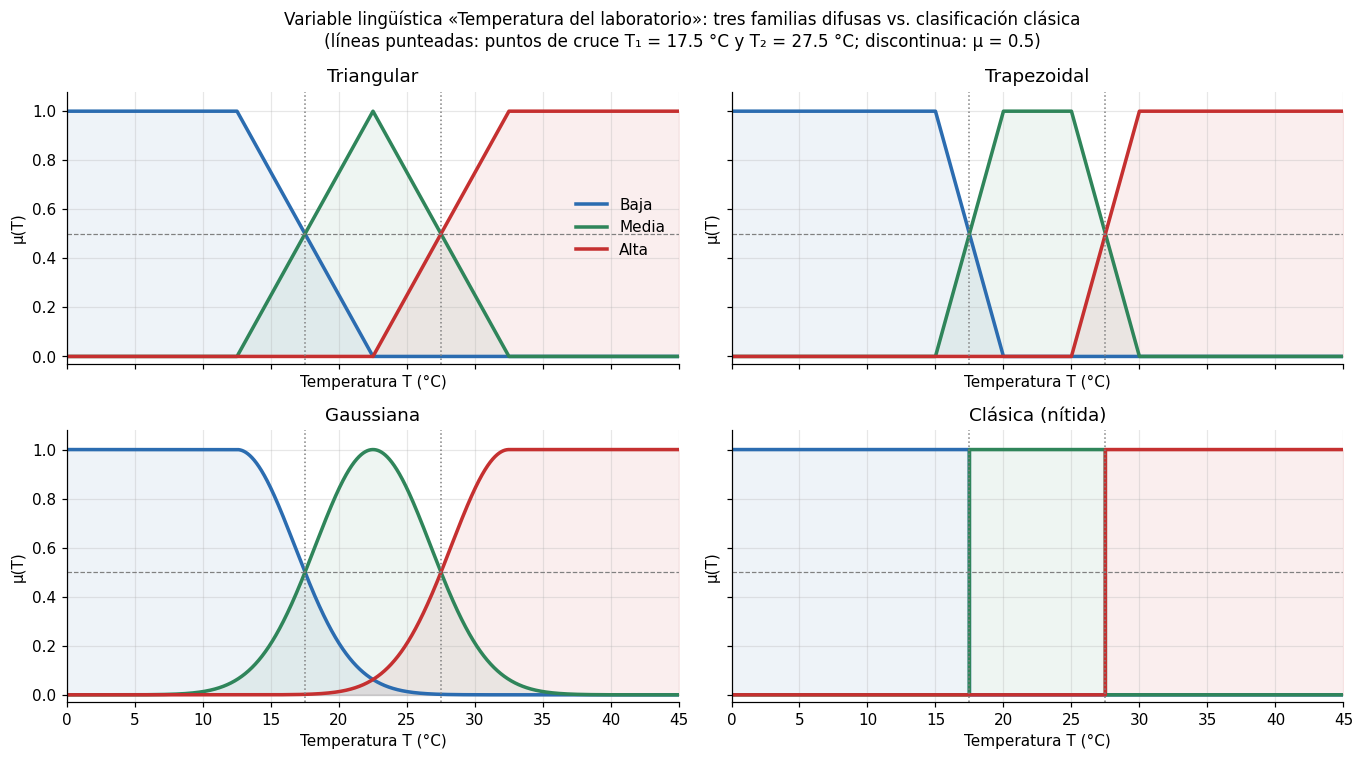

In [5]:
# ── 6.3  Gráficas de las cuatro representaciones ────────────────────────────
def graficar_variable(ax, var, titulo, x=None):
    x = var.malla() if x is None else x
    for t in var.terminos:
        y = var.mu(t, x)
        ax.plot(x, y, lw=2.3, color=COLORES.get(t), label=t)
        ax.fill_between(x, y, color=COLORES.get(t), alpha=0.08)
    for c in (T1, T2):
        ax.axvline(c, ls=":", color="gray", lw=1)
    ax.axhline(0.5, ls="--", color="gray", lw=0.8)
    ax.set(title=titulo, xlabel="Temperatura T (°C)", ylabel="μ(T)", ylim=(-0.03, 1.08), xlim=X)

fig, axs = plt.subplots(2, 2, figsize=(12.5, 7), sharex=True, sharey=True)
for ax, (nombre, var) in zip(axs.flat, todas.items()):
    graficar_variable(ax, var, nombre)
axs[0, 0].legend(loc="center right")
fig.suptitle("Variable lingüística «Temperatura del laboratorio»: tres familias difusas vs. clasificación clásica\n"
             "(líneas punteadas: puntos de cruce T₁ = 17.5 °C y T₂ = 27.5 °C; discontinua: μ = 0.5)", fontsize=11)
plt.tight_layout(); plt.show()

**Interpretación.**
- Las tres familias difusas comparten los puntos de cruce ($\mu=0.5$ en 17.5 °C y 27.5 °C), es decir, **la misma semántica de frontera**. Se diferencian en *cómo* ocurre la transición.
- La **triangular** tiene un único prototipo y transiciones de 10 °C.
- La **trapezoidal** tiene una meseta $[20,25]$ °C y transiciones de 5 °C, más «abruptas».
- La **gaussiana** es suave y derivable, pero sus colas se solapan con términos no adyacentes: *Baja* y *Alta* no son exactamente cero en 22.5 °C.
- La **clásica** es una escalera. Cada temperatura pertenece a un único término y la transición es un salto.

### 6.4 Grados de pertenencia para temperaturas representativas

Triangular                  Trapezoidal                 Gaussiana                         Clásica                
             Baja Media  Alta   Σμ        Baja Media Alta   Σμ      Baja   Media    Alta      Σμ    Baja Media Alta   Σμ
T (°C)                                                                                                                  
5.0          1.00  0.00  0.00  1.0         1.0   0.0  0.0  1.0    1.0000  0.0002  0.0000  1.0002     1.0   0.0  0.0  1.0
12.5         1.00  0.00  0.00  1.0         1.0   0.0  0.0  1.0    1.0000  0.0625  0.0000  1.0625     1.0   0.0  0.0  1.0
15.0         0.75  0.25  0.00  1.0         1.0   0.0  0.0  1.0    0.8409  0.2102  0.0002  1.0513     1.0   0.0  0.0  1.0
17.0         0.55  0.45  0.00  1.0         0.6   0.4  0.0  1.0    0.5704  0.4323  0.0013  1.0039     1.0   0.0  0.0  1.0
17.5         0.50  0.50  0.00  1.0         0.5   0.5  0.0  1.0    0.5000  0.5000  0.0020  1.0020     0.0   1.0  0.0  1.0
18.0         0.45  0.55  0.00  1.0         0.4   0.6  0.0  1.0    0.4323  0.5704  0.0029  1.0056     0.0   1.0  0.0  1.0
20.0         0.25  0.75  0.00  1.0         0.0   1.0  0.0  1.0    0.2102  0.8409  0.0131  1.0643     0.0   1.0  0.0  1.0
22.5         0.00  1.00  0.00  1.0         0.0   1.0  0.0  1.0    0.0625  1.0000  0.0625  1.1250     0.0   1.0  0.0  1.0
25.0         0.00  0.75  0.25  1.0         0.0   1.0  0.0  1.0    0.0131  0.8409  0.2102  1.0643     0.0   1.0  0.0  1.0
26.0         0.00  0.65  0.35  1.0         0.0   0.8  0.2  1.0    0.0064  0.7120  0.3099  1.0283     0.0   1.0  0.0  1.0
27.5         0.00  0.50  0.50  1.0         0.0   0.5  0.5  1.0    0.0020  0.5000  0.5000  1.0020     0.0   0.0  1.0  1.0
30.0         0.00  0.25  0.75  1.0         0.0   0.0  1.0  1.0    0.0002  0.2102  0.8409  1.0513     0.0   0.0  1.0  1.0
35.0         0.00  0.00  1.00  1.0         0.0   0.0  1.0  1.0    0.0000  0.0131  1.0000  1.0131     0.0   0.0  1.0  1.0
42.0         0.00  0.00  1.00  1.0         0.0   0.0  1.0  1.0    0.0000  0.0000  1.0000  1.0000     0.0   0.0  1.0  1.0

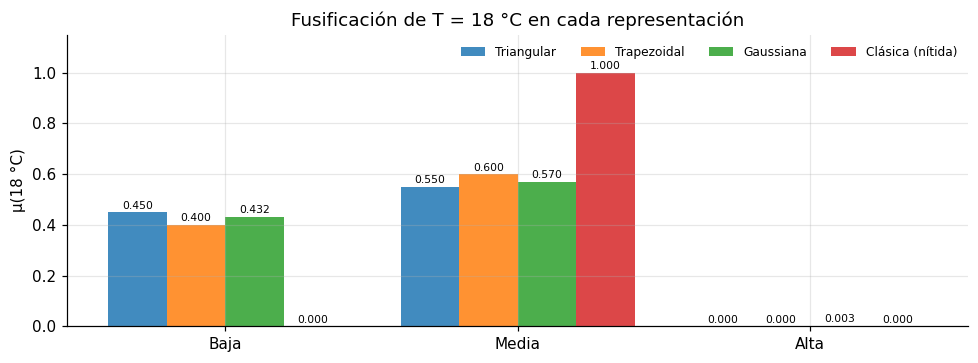

In [6]:
# ── 6.4  Tabla de fusificación ──────────────────────────────────────────────
T_muestra = np.array([5, 12.5, 15, 17, 17.5, 18, 20, 22.5, 25, 26, 27.5, 30, 35, 42], float)
cols = {}
for nombre, var in todas.items():
    corto = nombre.split(" ")[0]
    M = np.vstack([var.mu(t, T_muestra) for t in var.terminos])
    for t, fila in zip(var.terminos, M):
        cols[(corto, t)] = fila
    cols[(corto, "Σμ")] = M.sum(axis=0)
tabla_fus = pd.DataFrame(cols, index=pd.Index(T_muestra, name="T (°C)"))
display(tabla_fus.round(4))

# Gráfico de barras para T = 18 °C
T0 = 18.0
fig, ax = plt.subplots(figsize=(9, 3.4))
anchura = 0.2
for k, (nombre, var) in enumerate(todas.items()):
    g = var.fusificar(T0)
    pos = np.arange(3) + (k - 1.5) * anchura
    barras = ax.bar(pos, list(g.values()), anchura, label=nombre, alpha=0.85)
    ax.bar_label(barras, fmt="%.3f", fontsize=7, padding=1)
ax.set_xticks(range(3), ["Baja", "Media", "Alta"])
ax.set(ylabel="μ(18 °C)", ylim=(0, 1.15), title="Fusificación de T = 18 °C en cada representación")
ax.legend(ncol=4, fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

**Interpretación.**
- A 18 °C el modelo clásico afirma «Media» con certeza total (1) y niega «Baja» (0). Los tres modelos difusos coinciden cualitativamente en que la temperatura es **predominantemente Media, pero todavía algo Baja**: (0.55, 0.45) en la triangular, (0.6, 0.4) en la trapezoidal y ≈(0.57, 0.43) en la gaussiana.
- La suma $\sum\mu$ vale exactamente 1 en las familias triangular y trapezoidal (**partición de Ruspini**). En la gaussiana es ligeramente mayor que 1 y llega a 1.125 en 22.5 °C.
- **Los grados difusos no son probabilidades**: nada obliga a que sumen 1. La partición de Ruspini es una *propiedad de diseño* deseable, no un axioma.

### 6.5 Verificación numérica del ejemplo a mano (§4.3)

In [7]:
# ── 6.5  Recalcular con código todas las operaciones de §4.3 ─────────────────
def tabla_operaciones(a, b, lam=2.0, w=2.0):
    return {
        "c estándar (a)":           c_estandar(a),
        f"c Sugeno λ={lam:g} (a)":  c_sugeno(a, lam),
        f"c Yager w={w:g} (a)":     c_yager(a, w),
        "∩ min":                    i_min(a, b),
        "∩ producto":               i_prod(a, b),
        "∩ Łukasiewicz":            i_luk(a, b),
        "∩ drástica":               i_drastica(a, b),
        f"∩ Yager w={w:g}":         i_yager(a, b, w),
        "∪ max":                    u_max(a, b),
        "∪ suma algebraica":        u_suma_alg(a, b),
        "∪ suma acotada":           u_acotada(a, b),
        "∪ drástica":               u_drastica(a, b),
        f"∪ Yager w={w:g}":         u_yager(a, b, w),
        "contradicción estándar min(b, 1−b)":   i_min(b, 1 - b),
        "tercero excluido estándar max(b, 1−b)": u_max(b, 1 - b),
        "contradicción Łuk. max(0, b+(1−b)−1)": i_luk(b, 1 - b),
        "tercero excluido Łuk. min(1, b+1−b)":  u_acotada(b, 1 - b),
    }

trap = familias["Trapezoidal"]
g18, g26 = trap.fusificar(18), trap.fusificar(26)
print("T = 18 °C →", g18, "\nT = 26 °C →", g26)
ops = pd.DataFrame({
    "T=18: a=Baja, b=Media": {k: float(v) for k, v in tabla_operaciones(g18["Baja"], g18["Media"]).items()},
    "T=26: a=Media, b=Alta": {k: float(v) for k, v in tabla_operaciones(g26["Media"], g26["Alta"]).items()},
})
display(ops.round(4))

# Comprobaciones explícitas del cálculo a mano
a, b = g18["Baja"], g18["Media"]
assert np.isclose(c_estandar(i_min(a, b)), u_max(c_estandar(a), c_estandar(b)))          # De Morgan
assert np.isclose(min(1 - g18["Baja"], 1 - g18["Alta"]), g18["Media"])                   # ni Baja ni Alta
assert np.isclose(trap.mu("muy Alta", 26), 0.04) and np.isclose(trap.mu("algo Alta", 26), np.sqrt(0.2))
print("✔ De Morgan, «ni Baja ni Alta» = Media y modificadores verificados en los puntos del ejemplo.")

T = 18 °C → {'Baja': 0.4, 'Media': 0.6, 'Alta': 0.0} 
T = 26 °C → {'Baja': 0.0, 'Media': 0.8, 'Alta': 0.2}


,"T=18: a=Baja, b=Media","T=26: a=Media, b=Alta"
c estándar (a),0.6000,0.2000
c Sugeno λ=2 (a),0.3333,0.0769
c Yager w=2 (a),0.9165,0.6000
∩ min,0.4000,0.2000
∩ producto,0.2400,0.1600
∩ Łukasiewicz,0.0000,0.0000
∩ drástica,0.0000,0.0000
∩ Yager w=2,0.2789,0.1754
∪ max,0.6000,0.8000
∪ suma algebraica,0.7600,0.8400


✔ De Morgan, «ni Baja ni Alta» = Media y modificadores verificados en los puntos del ejemplo.


**Interpretación.** Los valores coinciden con los calculados a mano en §4.3.
- A 26 °C ($a=0.8$, $b=0.2$) la suma acotada da $\min(1,\,1.0)=1$ y la intersección de Łukasiewicz da 0.
- Las operaciones «fuertes» (Łukasiewicz, drástica) son muy exigentes con la conjunción. Las operaciones estándar son las más «tolerantes» en la intersección y las más «conservadoras» en la unión.
- La **elección del operador cambia el resultado numérico** (para la intersección, desde 0 hasta 0.4 en el mismo punto). Esto confirma que las operaciones, igual que las funciones de pertenencia, dependen del contexto [KY, §3.1, p. 50].

### 6.6 Conceptos básicos: altura, soporte, núcleo, convexidad, α-cortes, cardinalidad y borrosidad

In [8]:
# ── 6.6a  Propiedades de cada término ───────────────────────────────────────
x = familias["Trapezoidal"].malla()               # malla fina: Δx = 0.01 °C
filas = []
for nombre, var in todas.items():
    for t in var.terminos:
        mu = var.mu(t, x)
        sop = x[mu > 1e-9]; nuc = x[mu >= 1 - 1e-12]
        filas.append({
            "Familia": nombre, "Término": t,
            "Altura h(A)": mu.max(),
            "Normal": bool(np.isclose(mu.max(), 1)),
            "Convexo (Teo. 1.1)": es_convexo(var.semantica[t], x),
            "Soporte numérico (μ>1e-9)": f"[{sop.min():.2f}, {sop.max():.2f}]",
            "Núcleo": f"[{nuc.min():.2f}, {nuc.max():.2f}]",
            "|A| = ∫μ dx (°C)": cardinalidad(mu, x),
            "Borrosidad f(A) (°C)": borrosidad(mu, x),
        })
props = pd.DataFrame(filas).set_index(["Familia", "Término"])
display(props.round(4))

# Grado de subconjunto (1.21): ¿en qué medida «muy Media» ⊆ Media y Media ⊆ «muy Media»?
for nombre, var in familias.items():
    m, mm = var.mu("Media", x), var.mu("muy Media", x)
    print(f"{nombre:12s}  S(muy Media, Media) = {subconjuntidad(mm, m, x):.3f}   "
          f"S(Media, muy Media) = {subconjuntidad(m, mm, x):.3f}")

Altura h(A)  Normal  Convexo (Teo. 1.1) Soporte numérico (μ>1e-9)          Núcleo  |A| = ∫μ dx (°C)  Borrosidad f(A) (°C)
Familia          Término                                                                                                                           
Triangular       Baja             1.0    True                True             [0.00, 22.49]   [0.00, 12.50]           17.5000                5.0000
                 Media            1.0    True                True            [12.51, 32.49]  [22.50, 22.50]           10.0000               10.0000
                 Alta             1.0    True                True            [22.51, 45.00]  [32.50, 45.00]           17.5000                5.0000
Trapezoidal      Baja             1.0    True                True             [0.00, 19.99]   [0.00, 15.00]           17.5000                2.5000
                 Media            1.0    True                True            [15.01, 29.99]  [20.00, 25.00]           10.0000                5.0000
                 Alta             1.0    True                True            [25.01, 45.00]  [30.00, 45.00]           17.5000                2.5000
Gaussiana        Baja             1.0    True                True             [0.00, 39.83]   [0.00, 12.50]           17.8223                4.4442
                 Media            1.0    True                True             [0.00, 45.00]  [22.50, 22.50]           10.6447                8.8883
                 Alta             1.0    True                True             [5.17, 45.00]  [32.50, 45.00]           17.8223                4.4442
Clásica (nítida) Baja             1.0    True                True             [0.00, 17.49]   [0.00, 17.49]           17.4950                0.0000
                 Media            1.0    True                True            [17.50, 27.49]  [17.50, 27.49]           10.0000                0.0000
                 Alta             1.0    True                True            [27.50, 45.00]  [27.50, 45.00]           17.5050                0.0000

Triangular    S(muy Media, Media) = 1.000   S(Media, muy Media) = 0.667
Trapezoidal   S(muy Media, Media) = 1.000   S(Media, muy Media) = 0.833
Gaussiana     S(muy Media, Media) = 1.000   S(Media, muy Media) = 0.707


**Interpretación.**
- Todos los términos son **normales** y **convexos**, como se espera de conceptos «unimodales» sobre una magnitud física.
- La **cardinalidad** de *Media* es prácticamente la misma en las tres familias: 10 °C en triangular y trapezoidal, ≈10.6 °C en gaussiana. Las tres representan una «cantidad» de temperaturas medias equivalente, a la anchura de la clase nítida (27.5 − 17.5 = 10 °C).
- La **borrosidad** sí cambia mucho: *Media* trapezoidal tiene $f=5$ °C, la triangular $f=10$ °C (el doble, como se predijo en §3.7) y la gaussiana un valor intermedio. Los términos nítidos tienen $f=0$.
- El soporte numérico de la gaussiana cubre casi todo $X$. El soporte teórico es $\mathbb R$, y el corte en $10^{-9}$ es un artefacto numérico.
- El **grado de subconjunto** confirma que «muy Media» $\subseteq$ Media con grado 1 (porque $\mu^2\le\mu$). La inclusión inversa solo se cumple parcialmente.

αA analítico       αA numérico  Anchura (°C)  |error| máx
α    Familia                                                                   
0.10 Triangular   [13.500, 31.500]  [13.500, 31.500]       18.0000       0.0000
     Trapezoidal  [15.500, 29.500]  [15.500, 29.500]       14.0000       0.0000
     Gaussiana    [13.387, 31.613]  [13.390, 31.610]       18.2262       0.0031
0.25 Triangular   [15.000, 30.000]  [15.000, 30.000]       15.0000       0.0000
     Trapezoidal  [16.250, 28.750]  [16.250, 28.750]       12.5000       0.0000
     Gaussiana    [15.429, 29.571]  [15.430, 29.570]       14.1421       0.0011
0.50 Triangular   [17.500, 27.500]  [17.500, 27.500]       10.0000       0.0000
     Trapezoidal  [17.500, 27.500]  [17.500, 27.500]       10.0000       0.0000
     Gaussiana    [17.500, 27.500]  [17.500, 27.500]       10.0000       0.0000
0.75 Triangular   [20.000, 25.000]  [20.000, 25.000]        5.0000       0.0000
     Trapezoidal  [18.750, 26.250]  [18.750, 26.250]        7.5000       0.0000
     Gaussiana    [19.279, 25.721]  [19.280, 25.720]        6.4423       0.0012
0.90 Triangular   [21.500, 23.500]  [21.500, 23.500]        2.0000       0.0000
     Trapezoidal  [19.500, 25.500]  [19.500, 25.500]        6.0000       0.0000
     Gaussiana    [20.551, 24.449]  [20.560, 24.440]        3.8988       0.0094
1.00 Triangular   [22.500, 22.500]  [22.500, 22.500]        0.0000       0.0000
     Trapezoidal  [20.000, 25.000]  [20.000, 25.000]        5.0000       0.0000
     Gaussiana    [22.500, 22.500]  [22.500, 22.500]        0.0000       0.0000

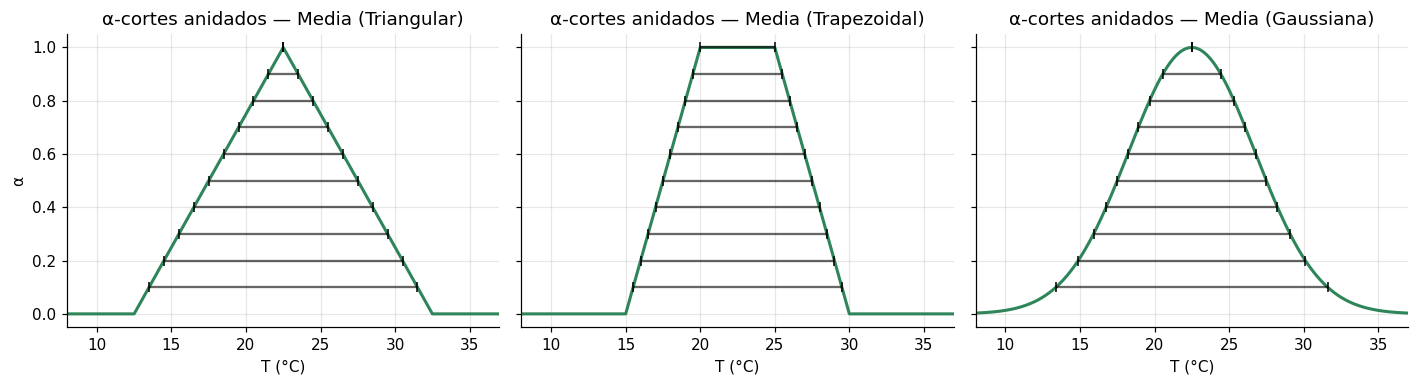

In [9]:
# ── 6.6b  α-cortes del término «Media»: analíticos (§3.1) vs. numéricos ──────
analitico = {
    "Triangular":  lambda a: (12.5 + 10 * a, 32.5 - 10 * a),
    "Trapezoidal": lambda a: (15 + 5 * a, 30 - 5 * a),
    "Gaussiana":   lambda a: (22.5 - SIGMA * np.sqrt(-2 * np.log(a)), 22.5 + SIGMA * np.sqrt(-2 * np.log(a))),
}
filas = []
for alfa in [0.1, 0.25, 0.5, 0.75, 0.9, 1.0]:
    for nombre, var in familias.items():
        lo_a, hi_a = analitico[nombre](alfa)
        lo_n, hi_n = alfa_corte(var.mu("Media", x), x, alfa)
        filas.append({"α": alfa, "Familia": nombre,
                      "αA analítico": f"[{lo_a:.3f}, {hi_a:.3f}]",
                      "αA numérico":  f"[{lo_n:.3f}, {hi_n:.3f}]",
                      "Anchura (°C)": hi_a - lo_a,
                      "|error| máx": max(abs(lo_a - lo_n), abs(hi_a - hi_n))})
cortes = pd.DataFrame(filas).set_index(["α", "Familia"])
display(cortes.round(4))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (nombre, var) in zip(axs, familias.items()):
    ax.plot(x, var.mu("Media", x), color=COLORES["Media"], lw=2)
    for alfa in np.linspace(0.1, 1.0, 10):
        lo, hi = alfa_corte(var.mu("Media", x), x, alfa)
        ax.hlines(alfa, lo, hi, color="k", lw=1.5, alpha=0.6)
        ax.plot([lo, hi], [alfa, alfa], "k|", ms=6)
    ax.set(title=f"α-cortes anidados — Media ({nombre})", xlabel="T (°C)", xlim=(8, 37))
axs[0].set_ylabel("α"); plt.tight_layout(); plt.show()

**Interpretación.**
- Los α-cortes numéricos coinciden con las fórmulas cerradas de §3.1. El error es del orden de la resolución de la malla (0.01 °C).
- Los cortes forman **familias anidadas**, como exige [KY, (1.9)].
- En la trapezoidal, el **0.5-corte** es $[17.5,\,27.5]$: la clase nítida de *Media*, salvo el extremo derecho. Esto formaliza la idea de §3.8: la clasificación clásica corresponde a «cortar» el conjunto difuso a un nivel fijo y descartar el resto.
- La triangular y la gaussiana degeneran en un punto cuando $\alpha=1$, porque su núcleo es $\{22.5\}$.

### 6.7 Teorema de descomposición: reconstrucción a partir de α-cortes [KY, Teo. 2.5]

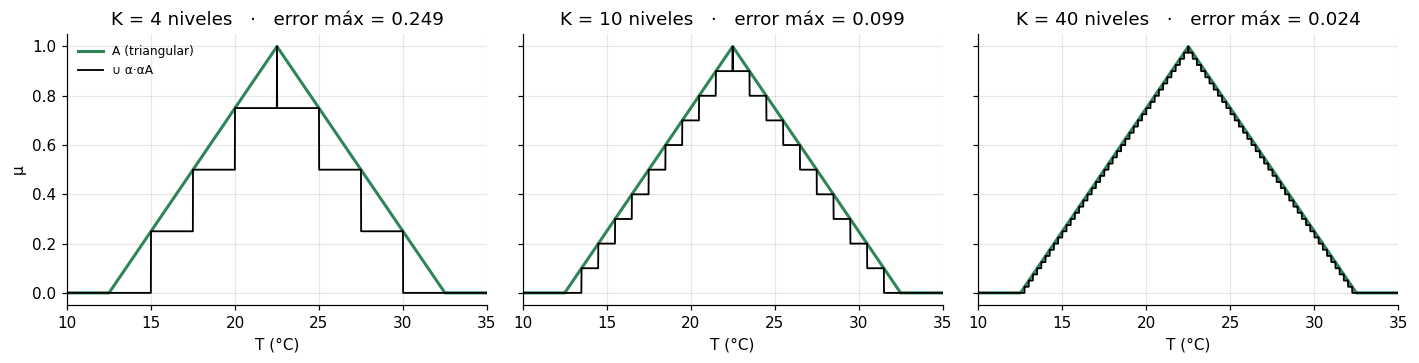

In [10]:
# ── 6.7  A(x) = sup_α α·χ_{αA}(x): reconstrucción con K niveles ──────────────
A = familias["Triangular"].mu("Media", x)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, K in zip(axs, [4, 10, 40]):
    alfas = np.arange(1, K + 1) / K
    recon = np.max([al * (A >= al - 1e-12) for al in alfas], axis=0)   # unión estándar de los α·αA
    err = np.abs(A - recon).max()
    ax.plot(x, A, color=COLORES["Media"], lw=2, label="A (triangular)")
    ax.plot(x, recon, color="k", lw=1.2, label="∪ α·αA")
    ax.set(title=f"K = {K} niveles   ·   error máx = {err:.3f}", xlabel="T (°C)", xlim=(10, 35))
axs[0].set_ylabel("μ"); axs[0].legend(loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

**Interpretación.**
- Con $K$ niveles equiespaciados, la unión de los conjuntos nítidos escalados $\alpha\cdot{}^{\alpha}A$ aproxima $A$ con error máximo $1/K$, y tiende a la reconstrucción exacta cuando $K\to\infty$.
- **Un conjunto difuso es equivalente a una familia anidada de conjuntos nítidos**. Es la razón por la que la aritmética de números difusos se reduce a aritmética de intervalos [KY, §4.3].
- En el sentido inverso, una sola clasificación nítida (un solo corte) conserva **un único nivel** de la información.

### 6.8 Coherencia de las particiones difusas (auditoría de diseño)

Para evaluar si las funciones elegidas son **coherentes** se usan criterios habituales en el diseño de particiones difusas, que se desprenden de §2.5 y §3:

| Criterio | Qué mide |
|---|---|
| **Normalidad** | todo término tiene al menos un prototipo con $\mu=1$ |
| **Convexidad** | cada término representa un concepto «unimodal» (Teo. 1.1) |
| **Cobertura** $\varepsilon=\min_x\max_t\mu_t(x)$ | todo valor de $X$ está descrito por algún término al menos en grado $\varepsilon$ |
| **Ruspini** $\max_x\lvert\sum_t\mu_t-1\rvert$ | los términos se reparten la pertenencia sin huecos ni redundancia |
| **Solapamiento** | los términos adyacentes se solapan (transición gradual), pero los no adyacentes no deberían |
| **Identidad lingüística** | *Media* $=\overline{\text{Baja}}\cap\overline{\text{Alta}}$ («ni fría ni caliente») |
| **Pendiente máxima** $L$ | sensibilidad del grado a errores en la variable base (§5.1) |

,Triangular,Trapezoidal,Gaussiana,Clásica (nítida)
Normalidad (h = 1 en todo término),True,True,True,True
Convexidad (Teo. 1.1),True,True,True,True
Cobertura ε = min_x max_t μ_t,0.5000,0.5000,0.5000,1.0000
Ruspini: max |Σμ − 1|,0.0000,0.0000,0.1250,0.0000
Solape máx. Baja ∩ Media (adyacentes),0.5000,0.5000,0.5000,0.0000
Solape máx. Baja ∩ Alta (no adyac.),0.0000,0.0000,0.0625,0.0000
Cruce Baja/Media (°C),17.5000,17.5000,17.5000,10.0000
Cruce Media/Alta (°C),27.5000,27.5000,27.5000,22.5000
Error máx. Media vs ¬Baja ∩ ¬Alta,0.0000,0.0000,0.0785,0.0000
Pendiente máx. de Media L (1/°C),0.1000,0.2000,0.1428,50.0000


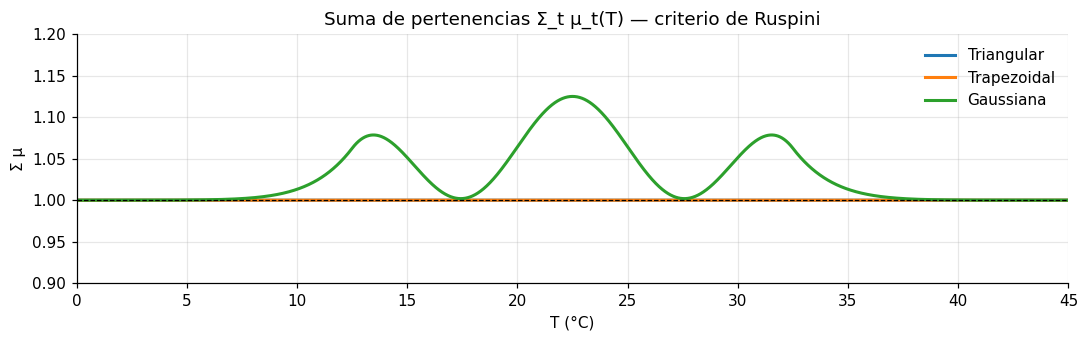

In [11]:
# ── 6.8  Auditoría de coherencia de cada partición ──────────────────────────
def auditoria(var, x):
    B, M, A = (var.mu(t, x) for t in var.terminos)
    izq, der = (x >= 10) & (x <= 22.5), (x >= 22.5) & (x <= 35)
    return {
        "Normalidad (h = 1 en todo término)":    bool(all(np.isclose(m.max(), 1) for m in (B, M, A))),
        "Convexidad (Teo. 1.1)":                 all(es_convexo(var.semantica[t], x) for t in var.terminos),
        "Cobertura ε = min_x max_t μ_t":         np.max([B, M, A], axis=0).min(),
        "Ruspini: max |Σμ − 1|":                 np.abs(B + M + A - 1).max(),
        "Solape máx. Baja ∩ Media (adyacentes)": np.minimum(B, M).max(),
        "Solape máx. Baja ∩ Alta (no adyac.)":   np.minimum(B, A).max(),
        "Cruce Baja/Media (°C)":                 x[izq][np.argmin(np.abs(B - M)[izq])],
        "Cruce Media/Alta (°C)":                 x[der][np.argmin(np.abs(M - A)[der])],
        "Error máx. Media vs ¬Baja ∩ ¬Alta":     np.abs(M - np.minimum(1 - B, 1 - A)).max(),
        "Pendiente máx. de Media L (1/°C)":      np.abs(np.gradient(M, x)).max(),
        "Borrosidad f(Media) (°C)":              borrosidad(M, x),
    }

aud = pd.DataFrame({nombre: auditoria(var, x) for nombre, var in todas.items()})
display(aud.map(lambda v: f"{v:.4f}" if isinstance(v, (float, np.floating)) else v))

fig, ax = plt.subplots(figsize=(10, 3.2))
for nombre, var in familias.items():
    ax.plot(x, sum(var.mu(t, x) for t in var.terminos), lw=2, label=nombre)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set(title="Suma de pertenencias Σ_t μ_t(T) — criterio de Ruspini", xlabel="T (°C)", ylabel="Σ μ",
       ylim=(0.9, 1.2), xlim=X); ax.legend(); plt.tight_layout(); plt.show()

**Interpretación de la auditoría.**
- **Triangular y trapezoidal** cumplen todos los criterios. Son particiones de Ruspini exactas, con cobertura $\varepsilon=0.5$ (el mínimo está en los puntos de cruce), solapamiento solo entre términos adyacentes y la identidad lingüística *Media* = «ni Baja ni Alta» sin error.
- **Gaussiana**: es normal, convexa y tiene la misma cobertura, pero **viola el criterio de Ruspini** (la suma llega a 1.125). Además, *Baja* y *Alta* se solapan (0.0625 en 22.5 °C): una temperatura perfectamente media es «Baja» y «Alta» en grado 1/16. Por eso la identidad *Media* = ¬Baja ∩ ¬Alta solo se cumple de forma aproximada. Es el precio de la suavidad ($C^\infty$) y de las colas infinitas.
- **Clásica**: cumple trivialmente Ruspini y cobertura ($\varepsilon=1$), con solapamiento y borrosidad nulos. Su pendiente numérica, $\approx1/(2\Delta x)=50\ ^\circ\mathrm C^{-1}$, crece sin límite al refinar la malla: es la huella del **salto**.
- La pendiente máxima de *Media* ordena las familias por sensibilidad al error de medida: triangular (0.1) < gaussiana (≈0.143) < trapezoidal (0.2) ≪ nítida (∞).

### 6.9 Operaciones difusas: complementos, intersecciones y uniones

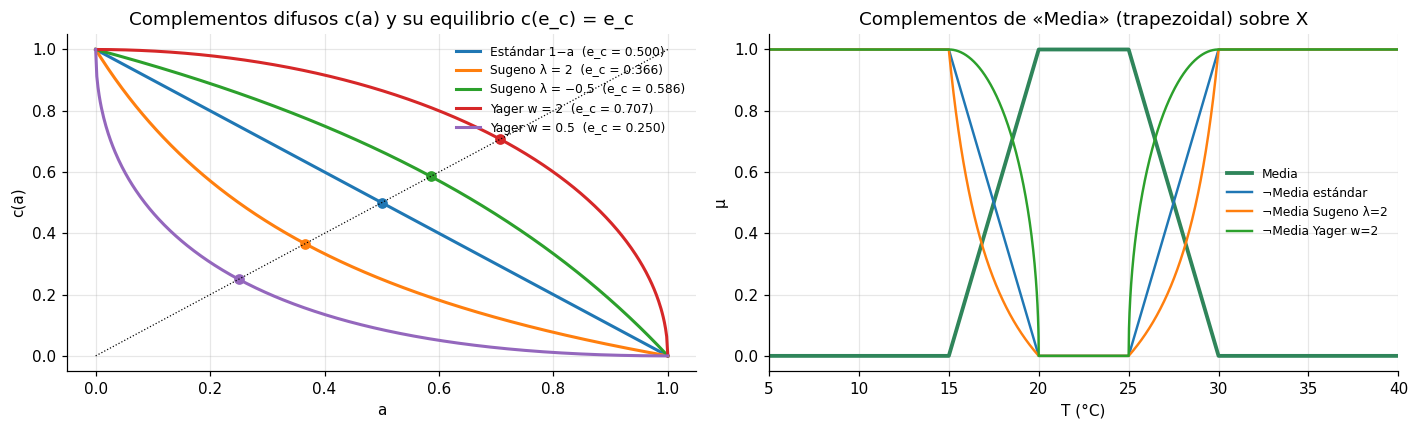

Estándar 1−a     involutivo: True   equilibrio: 0.5000   c(e) − e = +0.0e+00
Sugeno λ = 2     involutivo: True   equilibrio: 0.3660   c(e) − e = +1.1e-16
Sugeno λ = −0.5  involutivo: True   equilibrio: 0.5858   c(e) − e = +2.2e-16
Yager w = 2      involutivo: True   equilibrio: 0.7071   c(e) − e = -1.1e-16
Yager w = 0.5    involutivo: True   equilibrio: 0.2500   c(e) − e = +0.0e+00


In [12]:
# ── 6.9a  Complementos y sus equilibrios (§3.2) ─────────────────────────────
a = np.linspace(0, 1, 501)
compl = {
    "Estándar 1−a":    (c_estandar(a), 0.5),
    "Sugeno λ = 2":    (c_sugeno(a, 2),    (np.sqrt(3) - 1) / 2),
    "Sugeno λ = −0.5": (c_sugeno(a, -0.5), (np.sqrt(0.5) - 1) / -0.5),
    "Yager w = 2":     (c_yager(a, 2),     0.5 ** (1 / 2)),
    "Yager w = 0.5":   (c_yager(a, 0.5),   0.5 ** (1 / 0.5)),
}
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for nombre, (y, e) in compl.items():
    l, = axs[0].plot(a, y, lw=2, label=f"{nombre}  (e_c = {e:.3f})")
    axs[0].plot(e, e, "o", color=l.get_color())
axs[0].plot(a, a, "k:", lw=0.8)
axs[0].set(title="Complementos difusos c(a) y su equilibrio c(e_c) = e_c", xlabel="a", ylabel="c(a)")
axs[0].legend(fontsize=8)

var = familias["Trapezoidal"]; m = var.mu("Media", x)
axs[1].plot(x, m, color=COLORES["Media"], lw=2.5, label="Media")
for nombre, f in [("¬Media estándar", c_estandar), ("¬Media Sugeno λ=2", lambda v: c_sugeno(v, 2)),
                  ("¬Media Yager w=2", lambda v: c_yager(v, 2))]:
    axs[1].plot(x, f(m), lw=1.6, label=nombre)
axs[1].set(title="Complementos de «Media» (trapezoidal) sobre X", xlabel="T (°C)", ylabel="μ", xlim=(5, 40))
axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()

# verificación de involución (c4) y unicidad del equilibrio
for nombre, (y, e) in compl.items():
    f = {"Estándar 1−a": c_estandar, "Sugeno λ = 2": lambda v: c_sugeno(v, 2),
         "Sugeno λ = −0.5": lambda v: c_sugeno(v, -0.5), "Yager w = 2": lambda v: c_yager(v, 2),
         "Yager w = 0.5": lambda v: c_yager(v, 0.5)}[nombre]
    print(f"{nombre:16s} involutivo: {np.allclose(f(f(a)), a)}   equilibrio: {e:.4f}   c(e) − e = {float(f(e) - e):+.1e}")

**Interpretación.**
- Los cinco complementos son **involutivos** (axioma c4) y tienen un único equilibrio (Teos. 3.2 y 3.4).
- El equilibrio deja de ser 0.5 fuera del caso estándar. Con Sugeno $\lambda=2$, la «negación» es más severa: $e_c\approx0.366$. Con Yager $w=2$ es más permisiva: $e_c\approx0.707$.
- Sobre $X$, «no Media» toma valores distintos según el complemento, salvo donde *Media* vale exactamente 0 o 1 (axioma c1).
- Para el laboratorio se adopta el **complemento estándar**: es el único sin parámetros adicionales que justificar, su equilibrio en 0.5 coincide con los puntos de cruce de diseño, y no amplifica errores (§6.15).

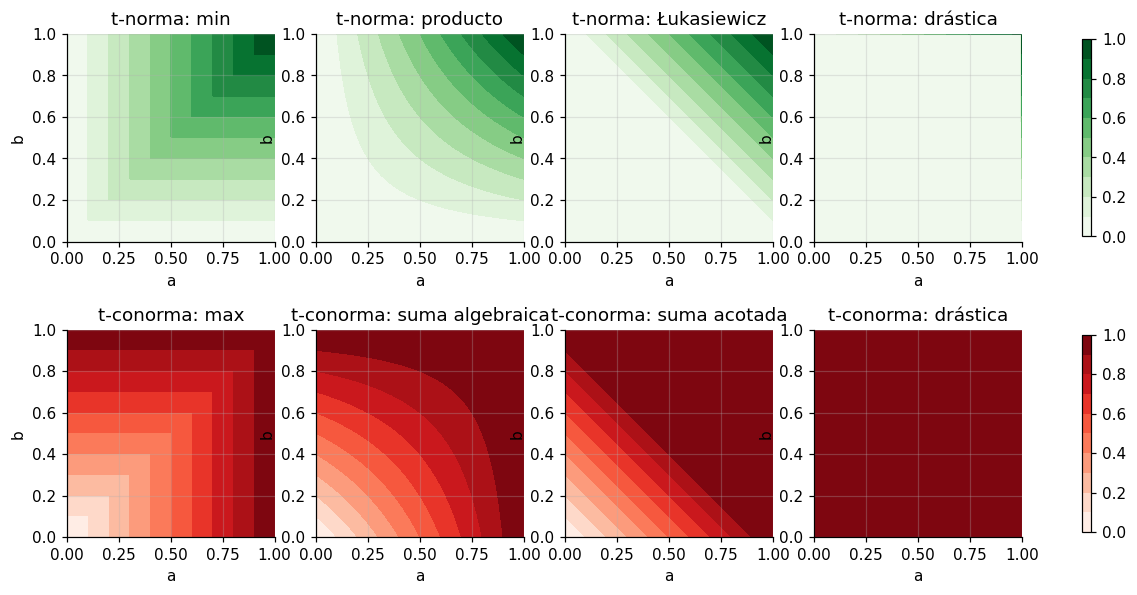

In [13]:
# ── 6.9b  t-normas y t-conormas: superficies sobre [0,1]² (cf. [KY] Figs. 3.6 y 3.10) ──
g = np.linspace(0, 1, 201); aa, bb = np.meshgrid(g, g)
tnormas  = {"min": i_min, "producto": i_prod, "Łukasiewicz": i_luk, "drástica": i_drastica}
tconorms = {"max": u_max, "suma algebraica": u_suma_alg, "suma acotada": u_acotada, "drástica": u_drastica}
fig, axs = plt.subplots(2, 4, figsize=(14, 6.4))
for ax, (n, f) in zip(axs[0], tnormas.items()):
    cs = ax.contourf(aa, bb, f(aa, bb), levels=np.linspace(0, 1, 11), cmap="Greens")
    ax.set(title=f"t-norma: {n}", xlabel="a", ylabel="b", aspect="equal")
for ax, (n, f) in zip(axs[1], tconorms.items()):
    cs2 = ax.contourf(aa, bb, f(aa, bb), levels=np.linspace(0, 1, 11), cmap="Reds")
    ax.set(title=f"t-conorma: {n}", xlabel="a", ylabel="b", aspect="equal")
fig.colorbar(cs, ax=axs[0].tolist(), shrink=0.8); fig.colorbar(cs2, ax=axs[1].tolist(), shrink=0.8)
plt.show()

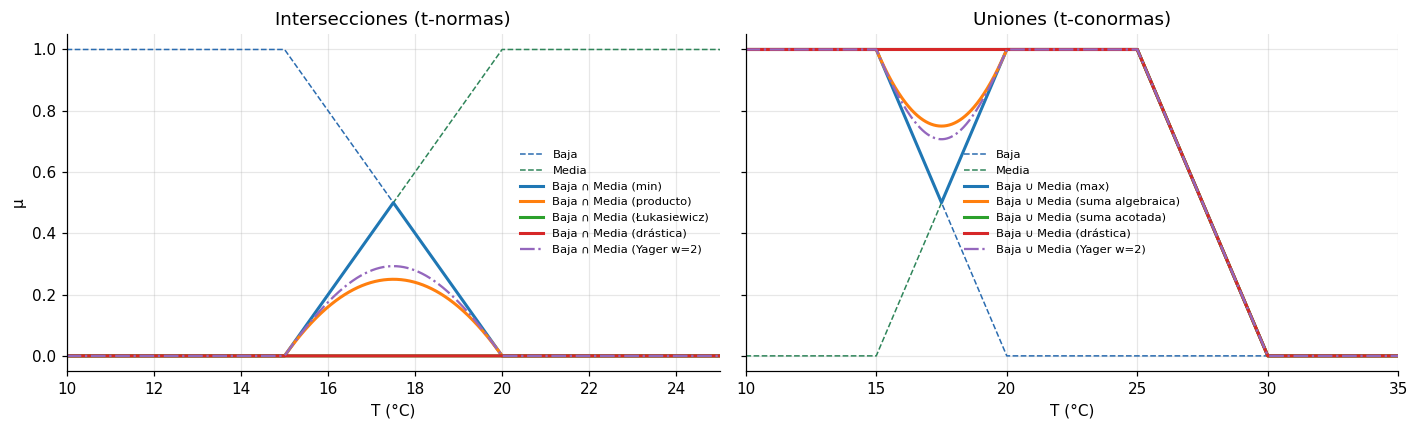

In [14]:
# ── 6.9c  Intersección y unión de «Baja» y «Media» sobre el universo X ───────
var = familias["Trapezoidal"]
B, M = var.mu("Baja", x), var.mu("Media", x)
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax in axs:
    ax.plot(x, B, color=COLORES["Baja"], lw=1, ls="--", label="Baja")
    ax.plot(x, M, color=COLORES["Media"], lw=1, ls="--", label="Media")
for n, f in tnormas.items():
    axs[0].plot(x, f(B, M), lw=2, label=f"Baja ∩ Media ({n})")
axs[0].plot(x, i_yager(B, M, 2), lw=1.5, ls="-.", label="Baja ∩ Media (Yager w=2)")
for n, f in tconorms.items():
    axs[1].plot(x, f(B, M), lw=2, label=f"Baja ∪ Media ({n})")
axs[1].plot(x, u_yager(B, M, 2), lw=1.5, ls="-.", label="Baja ∪ Media (Yager w=2)")
axs[0].set(title="Intersecciones (t-normas)", xlabel="T (°C)", ylabel="μ", xlim=(10, 25))
axs[1].set(title="Uniones (t-conormas)", xlabel="T (°C)", xlim=(10, 35))
for ax in axs: ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()

**Interpretación.**
- La intersección «Baja **y** Media» solo es no nula en la zona de transición $(15,20)$ °C. La t-norma estándar produce un «triángulo» de altura 0.5 en 17.5 °C, y las demás producen conjuntos cada vez más pequeños: producto (máx. 0.25), Yager $w=2$, y luego Łukasiewicz y drástica, que **anulan por completo** la intersección porque $\mu_B+\mu_M=1$ en toda la partición de Ruspini.
- Este último resultado tiene una lectura importante: con Łukasiewicz, en una partición de Ruspini «Baja y Media» es *imposible*. Esa operación trata los términos adyacentes como **mutuamente excluyentes**.
- La unión «Baja **o** Media» con la suma acotada vale exactamente 1 en $[0,30]$, lo que también refleja la partición de Ruspini. Con max hay una depresión a 0.5 en el punto de cruce.
- La elección del par $(i,u)$ es, por tanto, una **decisión semántica** que debe justificarse según el significado que se quiera dar a «y» / «o» [KY, §10.1, p. 280].

### 6.10 Verificación numérica de los teoremas de [KY]

Se evalúan las propiedades sobre una malla de $201\times201$ pares $(a,b)\in[0,1]^2$.

In [15]:
# ── 6.10  Verificación numérica de propiedades y teoremas ────────────────────
tol = 1e-12
res = []
def reg(propiedad, ok, ref, detalle=""):
    res.append({"Propiedad": propiedad, "¿Se cumple?": "✔" if ok else "✘", "Detalle": detalle, "Referencia [KY]": ref})

# Cotas de t-normas y t-conormas
ok = (np.all(i_drastica(aa, bb) <= i_luk(aa, bb) + tol) and np.all(i_luk(aa, bb) <= i_prod(aa, bb) + tol)
      and np.all(i_prod(aa, bb) <= i_min(aa, bb) + tol))
reg("i_drást ≤ máx(0,a+b−1) ≤ ab ≤ min(a,b)", ok, "Teo. 3.10, p. 65")
ok = (np.all(u_max(aa, bb) <= u_suma_alg(aa, bb) + tol) and np.all(u_suma_alg(aa, bb) <= u_acotada(aa, bb) + tol)
      and np.all(u_acotada(aa, bb) <= u_drastica(aa, bb) + tol))
reg("max(a,b) ≤ a+b−ab ≤ min(1,a+b) ≤ u_drást", ok, "Teo. 3.15, p. 78")
for w in [0.5, 1, 2, 5, 50]:
    ok = np.all(i_drastica(aa, bb) <= i_yager(aa, bb, w) + tol) and np.all(i_yager(aa, bb, w) <= i_min(aa, bb) + tol)
    reg(f"Yager w={w:g}: i_drást ≤ i_w ≤ min", ok, "Teo. 3.12, p. 70")
reg("Yager w=1 coincide con Łukasiewicz", np.allclose(i_yager(aa, bb, 1), i_luk(aa, bb)), "p. 70",
    f"error máx {np.abs(i_yager(aa, bb, 1) - i_luk(aa, bb)).max():.1e}")
reg("Yager w→∞ (w=500) → min", np.abs(i_yager(aa, bb, 500) - i_min(aa, bb)).max() < 2e-3, "Teo. 3.12",
    f"error máx {np.abs(i_yager(aa, bb, 500) - i_min(aa, bb)).max():.1e}")

# Idempotencia
reg("min es idempotente: min(a,a) = a", np.allclose(i_min(g, g), g), "Teo. 3.9")
reg("producto NO es idempotente", not np.allclose(i_prod(g, g), g), "Teo. 3.9",
    f"máx |a² − a| = {np.abs(g**2 - g).max():.2f}")

# De Morgan (ternas duales)
def err_demorgan(i, u, c):
    return max(np.abs(c(i(aa, bb)) - u(c(aa), c(bb))).max(), np.abs(c(u(aa, bb)) - i(c(aa), c(bb))).max())
cs_ = c_estandar; csug = lambda v: c_sugeno(v, 2)
for desc, (i, u, c), ref in [
        ("(min, max, c_estándar)", (i_min, u_max, cs_), "(3.27)-(3.28)"),
        ("(ab, a+b−ab, c_estándar)", (i_prod, u_suma_alg, cs_), "p. 83"),
        ("(Łuk., suma acotada, c_estándar)", (i_luk, u_acotada, cs_), "p. 83"),
        ("(drástica, drástica, c_estándar)", (i_drastica, u_drastica, cs_), "p. 83"),
        ("(min, max, Sugeno λ=2)", (i_min, u_max, csug), "Teo. 3.19")]:
    e = err_demorgan(i, u, c); reg(f"Terna dual {desc}", e < 1e-9, ref, f"error máx {e:.1e}")
e = err_demorgan(i_prod, u_max, cs_)
reg("(ab, max, c_estándar) NO es terna dual (control negativo)", e > 1e-3, "def. (3.27)", f"error máx {e:.3f}")

# Teorema 3.20: t-conorma dual generada desde ab y Sugeno λ=2 → clase de Hamacher
lam = 2.0
u_gen = c_sugeno(i_prod(c_sugeno(aa, lam), c_sugeno(bb, lam)), lam)
u_ham = (aa + bb + (lam - 1) * aa * bb) / (1 + lam * aa * bb)
reg("c(i(c(a),c(b))) con ab y Sugeno λ=2 = Hamacher", np.allclose(u_gen, u_ham), "Teo. 3.20, p. 85",
    f"error máx {np.abs(u_gen - u_ham).max():.1e}")
reg("… y es una t-conorma: u(a,0)=a y max ≤ u ≤ u_drást",
    np.allclose(u_gen[0, :], g) and np.all(u_max(aa, bb) <= u_gen + tol) and np.all(u_gen <= u_drastica(aa, bb) + tol),
    "Teo. 3.20")

# Leyes de contradicción / tercero excluido
reg("Estándar: contradicción min(a,1−a)=0", np.allclose(i_min(g, 1 - g), 0), "p. 25",
    f"sup min(a,1−a) = {i_min(g, 1 - g).max():.2f}")
reg("Estándar: tercero excluido max(a,1−a)=1", np.allclose(u_max(g, 1 - g), 1), "p. 25",
    f"inf max(a,1−a) = {u_max(g, 1 - g).min():.2f}")
reg("Łukasiewicz: contradicción y tercero excluido", np.allclose(i_luk(g, 1 - g), 0) and np.allclose(u_acotada(g, 1 - g), 1),
    "Teo. 3.23, p. 87")

# Distributividad
dd = 0.37
e_std = np.abs(i_min(aa, u_max(bb, dd)) - u_max(i_min(aa, bb), i_min(aa, dd))).max()
reg("Estándar: distributividad a∧(b∨d) = (a∧b)∨(a∧d)", e_std < 1e-12, "Retículo de De Morgan, p. 25", f"error máx {e_std:.1e}")
lhs, rhs = i_luk(0.5, u_acotada(0.5, 0.5)), u_acotada(i_luk(0.5, 0.5), i_luk(0.5, 0.5))
reg("Łukasiewicz: distributividad", np.isclose(lhs, rhs), "Teo. 3.24, p. 87",
    f"contraejemplo a=b=d=0.5: {float(lhs):.1f} ≠ {float(rhs):.1f}")

# Identidad lingüística sobre X
for nombre, var in familias.items():
    Bx, Mx, Ax = (var.mu(t, x) for t in var.terminos)
    e = np.abs(Mx - np.minimum(1 - Bx, 1 - Ax)).max()
    reg(f"{nombre}: Media = ¬Baja ∩ ¬Alta en todo X", e < 1e-12, "análogo a Fig. 1.12, p. 26", f"error máx {e:.4f}")

tabla_teo = pd.DataFrame(res)
display(tabla_teo.style.hide(axis="index"))

Propiedad,¿Se cumple?,Detalle,Referencia [KY]
"i_drást ≤ máx(0,a+b−1) ≤ ab ≤ min(a,b)",✔,,"Teo. 3.10, p. 65"
"max(a,b) ≤ a+b−ab ≤ min(1,a+b) ≤ u_drást",✔,,"Teo. 3.15, p. 78"
Yager w=0.5: i_drást ≤ i_w ≤ min,✔,,"Teo. 3.12, p. 70"
Yager w=1: i_drást ≤ i_w ≤ min,✔,,"Teo. 3.12, p. 70"
Yager w=2: i_drást ≤ i_w ≤ min,✔,,"Teo. 3.12, p. 70"
Yager w=5: i_drást ≤ i_w ≤ min,✔,,"Teo. 3.12, p. 70"
Yager w=50: i_drást ≤ i_w ≤ min,✔,,"Teo. 3.12, p. 70"
Yager w=1 coincide con Łukasiewicz,✔,error máx 1.1e-16,p. 70
Yager w→∞ (w=500) → min,✘,error máx 2.2e-01,Teo. 3.12
"min es idempotente: min(a,a) = a",✔,,Teo. 3.9


**Interpretación.** Todas las propiedades teóricas se confirman numéricamente.
- La **jerarquía de t-normas y t-conormas** se cumple (Teos. 3.10 y 3.15). La familia de Yager interpola entre sus extremos: con $w=1$ es Łukasiewicz y con $w\to\infty$ tiende a min.
- Las cuatro ternas duales clásicas satisfacen **De Morgan**. $(\min,\max)$ lo hace incluso con el complemento de Sugeno (Teo. 3.19). El control negativo $(ab,\max)$ falla, como debe.
- El Teo. 3.20 genera la **clase de Hamacher** a partir del producto y del complemento de Sugeno, reproduciendo el ejemplo de [KY, p. 85].
- **Ninguna terna conserva toda el álgebra de Boole.** La estándar pierde la contradicción y el tercero excluido (pero conserva la distributividad). Łukasiewicz recupera ambas leyes pero **pierde la distributividad** (Teo. 3.24).
- La identidad *Media* = ¬Baja ∩ ¬Alta es **exacta** en las particiones triangular y trapezoidal y **aproximada** en la gaussiana (error ≈ 0.06). Es un criterio de coherencia lingüística que favorece las particiones de Ruspini.

### 6.11 Modificadores lingüísticos: la gramática $g$ en acción

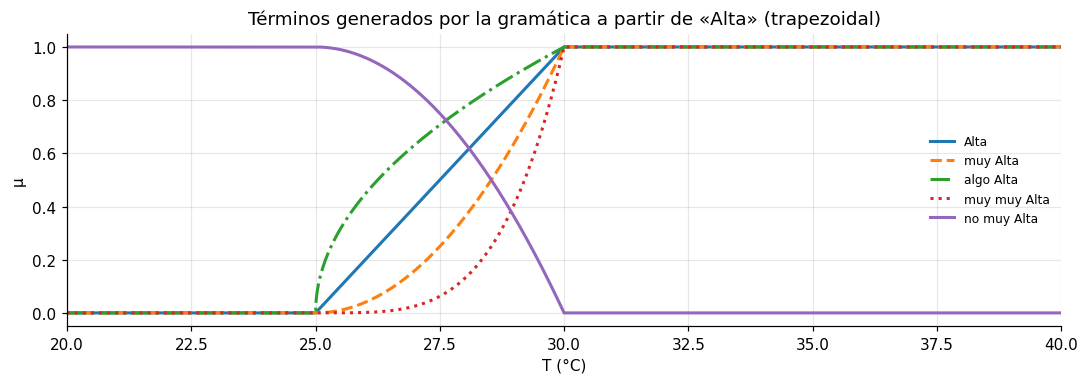

,Alta,muy Alta,algo Alta,no muy Alta
T (°C),,,,
26.0,0.2,0.04,0.4472,0.96
27.5,0.5,0.25,0.7071,0.75
28.0,0.6,0.36,0.7746,0.64
29.0,0.8,0.64,0.8944,0.36
30.0,1.0,1.00,1.0000,0.00


In [16]:
# ── 6.11  Hedges: muy / algo / no (§3.6) ────────────────────────────────────
var = familias["Trapezoidal"]
fig, ax = plt.subplots(figsize=(10, 3.6))
for t, estilo in [("Alta", "-"), ("muy Alta", "--"), ("algo Alta", "-."), ("muy muy Alta", ":"), ("no muy Alta", "-")]:
    ax.plot(x, var.mu(t, x), lw=2, ls=estilo, label=t)
ax.set(title="Términos generados por la gramática a partir de «Alta» (trapezoidal)", xlabel="T (°C)", ylabel="μ",
       xlim=(20, 40)); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

T_h = np.array([26, 27.5, 28, 29, 30])
display(pd.DataFrame({t: var.mu(t, T_h) for t in ["Alta", "muy Alta", "algo Alta", "no muy Alta"]},
                     index=pd.Index(T_h, name="T (°C)")).round(4))

**Interpretación.**
- «muy» ($\mu^2$) es un modificador **fuerte**: estrecha la zona de transición y reduce el grado. «algo» ($\sqrt\mu$) es **débil**: la amplía.
- A 26 °C: Alta = 0.2, «muy Alta» = 0.04, «algo Alta» ≈ 0.447. Las afirmaciones más exigentes son menos verdaderas, igual que en el ejemplo de [KY, p. 230].
- El núcleo y el soporte no cambian, porque $h(0)=0$ y $h(1)=1$. Por eso los modificadores **no pueden aplicarse a la clasificación nítida**: $0^2=0$ y $1^2=1$, de modo que «muy Media» sería idéntico a «Media».

### 6.12 Comparación directa: pertenencia binaria vs. grados de pertenencia

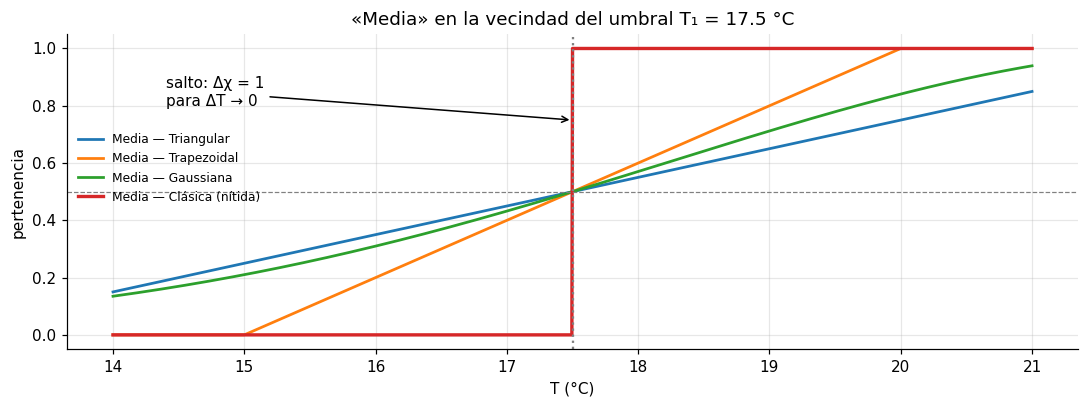

Triangular                         Trapezoidal                         Gaussiana                         Clásica                        
           μ_Baja μ_Media etiqueta argmax      μ_Baja μ_Media etiqueta argmax    μ_Baja μ_Media etiqueta argmax  μ_Baja μ_Media etiqueta argmax
T (°C)                                                                                                                                         
17.30       0.520   0.480            Baja       0.540   0.460            Baja    0.5279  0.4725            Baja     1.0     0.0            Baja
17.40       0.510   0.490            Baja       0.520   0.480            Baja    0.5139  0.4862            Baja     1.0     0.0            Baja
17.49       0.501   0.499            Baja       0.502   0.498            Baja    0.5014  0.4986            Baja     1.0     0.0            Baja
17.50       0.500   0.500            Baja       0.500   0.500            Baja    0.5000  0.5000            Baja     0.0     1.0           Media
17.60       0.490   0.510           Media       0.480   0.520           Media    0.4862  0.5139           Media     0.0     1.0           Media
17.70       0.480   0.520           Media       0.460   0.540           Media    0.4725  0.5279           Media     0.0     1.0           Media

Máximo |μ(T+0.1) − μ(T)| sobre X para «Media»:
   Triangular         0.0100
   Trapezoidal        0.0200
   Gaussiana          0.0143
   Clásica (nítida)   1.0000


In [17]:
# ── 6.12a  Comportamiento en la frontera T₁ = 17.5 °C ───────────────────────
xz = np.linspace(14, 21, 1401)
fig, ax = plt.subplots(figsize=(10, 3.8))
for nombre, var in todas.items():
    ax.plot(xz, var.mu("Media", xz), lw=2.2 if "Clás" in nombre else 1.8, label=f"Media — {nombre}")
ax.axvline(T1, color="gray", ls=":"); ax.axhline(0.5, color="gray", ls="--", lw=0.8)
ax.annotate("salto: Δχ = 1\npara ΔT → 0", xy=(17.5, 0.75), xytext=(14.4, 0.8), arrowprops=dict(arrowstyle="->"))
ax.set(title="«Media» en la vecindad del umbral T₁ = 17.5 °C", xlabel="T (°C)", ylabel="pertenencia")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.72)); plt.tight_layout(); plt.show()

T_f = np.array([17.3, 17.4, 17.49, 17.5, 17.6, 17.7])
filas = {}
for nombre, var in todas.items():
    M = np.vstack([var.mu(t, T_f) for t in var.terminos])
    filas[(nombre.split(" ")[0], "μ_Baja")] = M[0]
    filas[(nombre.split(" ")[0], "μ_Media")] = M[1]
    filas[(nombre.split(" ")[0], "etiqueta argmax")] = np.array(var.terminos)[M.argmax(axis=0)]
display(pd.DataFrame(filas, index=pd.Index(T_f, name="T (°C)")))

# Mayor cambio de μ_Media ante ΔT = 0.1 °C (sensibilidad local)
dT = 0.1
print("Máximo |μ(T+0.1) − μ(T)| sobre X para «Media»:")
for nombre, var in todas.items():
    print(f"   {nombre:18s} {np.abs(var.mu('Media', x + dT) - var.mu('Media', x)).max():.4f}")

In [18]:
# ── 6.12b  La clasificación nítida = máximo grado de la partición difusa (§3.8) ─
for nombre, var in familias.items():
    M = np.vstack([var.mu(t, x) for t in var.terminos])
    C = np.vstack([clasica.mu(t, x) for t in clasica.terminos])
    discrepancias = np.sum(M.argmax(axis=0) != C.argmax(axis=0))
    print(f"{nombre:12s}: etiquetas argmax distintas de la clasificación clásica en {discrepancias} de {x.size} puntos")

Triangular  : etiquetas argmax distintas de la clasificación clásica en 2 de 4501 puntos
Trapezoidal : etiquetas argmax distintas de la clasificación clásica en 2 de 4501 puntos
Gaussiana   : etiquetas argmax distintas de la clasificación clásica en 2 de 4501 puntos


**Interpretación.**

| Aspecto | Clasificación clásica (binaria) | Clasificación difusa (graduada) |
|---|---|---|
| Valores | $\{0,1\}$ | $[0,1]$ |
| En $T=17.49$ vs $17.50$ | Baja → Media (cambio total) | $\approx0.50\to0.50$ (cambio de $10^{-3}$) |
| Máx. $\lvert\Delta\mu\rvert$ para $\Delta T=0.1$ °C | **1** | 0.01–0.02 |
| Información sobre la «distancia» a la frontera | ninguna | el grado mismo |
| Modificadores («muy», «algo») | sin sentido | bien definidos |
| Leyes de Boole | todas | se pierden algunas (§6.10) |

- La **etiqueta de máximo grado** de las particiones difusas coincide con la clasificación clásica en casi todo $X$. Las discrepancias aparecen en un puñado de puntos de la malla: exactamente en los cruces, donde hay empate de grados y la convención de frontera de los intervalos decide; y, en la gaussiana, por la contribución de las colas. Esto confirma §3.8: **la clasificación clásica es la «defusificación por máximo» de la difusa**, y en ese paso se pierde la información graduada.
- La diferencia no está en *qué* etiqueta domina, sino en **cuánta confianza** se asigna y en **cómo varía** esa confianza.

### 6.13 Aplicación física: robustez frente a la incertidumbre del termómetro (Monte Carlo)

Se simulan $N=20\,000$ lecturas $T_{\text{med}}=T_{\text{real}}+\varepsilon$, con $\varepsilon\sim\mathcal N(0,\sigma_m^2)$ y $\sigma_m=0.4$ °C (orden de magnitud de la tolerancia de una Pt100 clase B, §5.1), para temperaturas reales en $[14,21]$ °C, alrededor del umbral $T_1$.

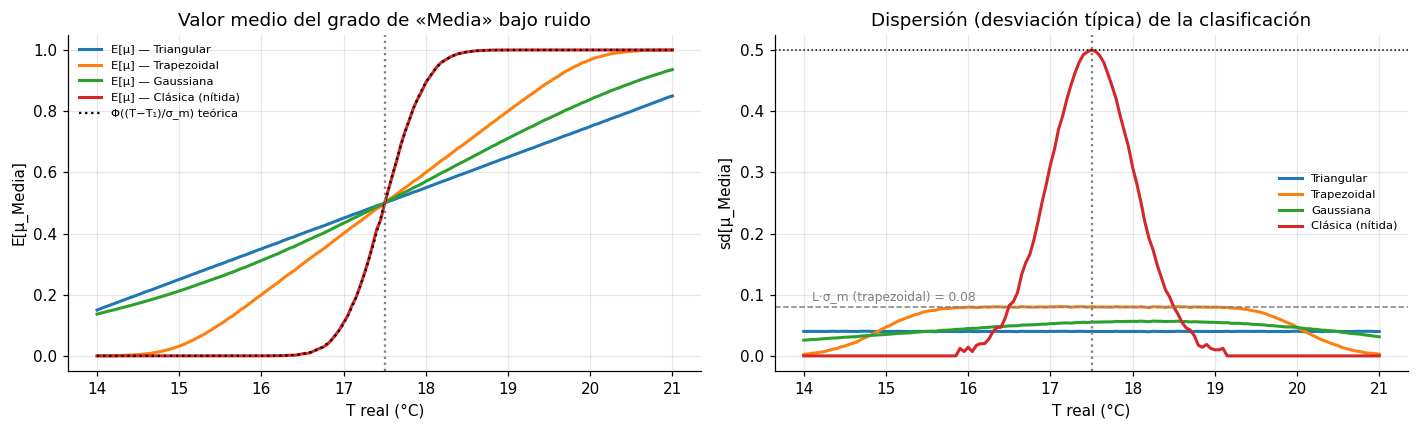

,P(etiqueta nítida = Media),sd nítida,sd triangular,sd trapezoidal,sd gaussiana
T real (°C),,,,,
16.5,0.0068,0.0825,0.0402,0.0803,0.0491
17.0,0.1094,0.3122,0.0401,0.0803,0.0527
17.5,0.4998,0.5000,0.0401,0.0803,0.0552
18.0,0.8937,0.3082,0.0400,0.0800,0.0565
18.5,0.9936,0.0801,0.0400,0.0799,0.0564


En la frontera, la dispersión nítida es 6.2× la trapezoidal y 12.5× la triangular.


In [19]:
# ── 6.13  Ruido de medición: dispersión de la clasificación nítida vs. difusa ──
SIGMA_M, N = 0.4, 20_000
T_real = np.linspace(14, 21, 141)
lect = T_real[None, :] + rng.normal(0, SIGMA_M, size=(N, 1)) * np.ones_like(T_real)[None, :]
lect = T_real[None, :] + rng.normal(0, SIGMA_M, size=(N, T_real.size))      # ruido independiente por lectura

resultados = {nombre: var.mu("Media", lect) for nombre, var in todas.items()}

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for nombre, R in resultados.items():
    axs[0].plot(T_real, R.mean(axis=0), lw=2, label=f"E[μ] — {nombre}")
    axs[1].plot(T_real, R.std(axis=0), lw=2, label=nombre)
axs[0].plot(T_real, norm.cdf((T_real - T1) / SIGMA_M), "k:", lw=1.5, label="Φ((T−T₁)/σ_m) teórica")
axs[0].set(title="Valor medio del grado de «Media» bajo ruido", xlabel="T real (°C)", ylabel="E[μ_Media]")
axs[1].axhline(0.5, color="k", ls=":", lw=1); axs[1].axhline(0.2 * SIGMA_M, color="gray", ls="--", lw=1)
axs[1].text(14.1, 0.2 * SIGMA_M + 0.01, "L·σ_m (trapezoidal) = 0.08", fontsize=8, color="gray")
axs[1].set(title="Dispersión (desviación típica) de la clasificación", xlabel="T real (°C)", ylabel="sd[μ_Media]")
for ax in axs: ax.axvline(T1, color="gray", ls=":"); ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()

idx = [np.argmin(np.abs(T_real - t)) for t in [16.5, 17.0, 17.5, 18.0, 18.5]]
mc = pd.DataFrame({
    "P(etiqueta nítida = Media)": resultados["Clásica (nítida)"].mean(axis=0)[idx],
    "sd nítida":                  resultados["Clásica (nítida)"].std(axis=0)[idx],
    "sd triangular":              resultados["Triangular"].std(axis=0)[idx],
    "sd trapezoidal":             resultados["Trapezoidal"].std(axis=0)[idx],
    "sd gaussiana":               resultados["Gaussiana"].std(axis=0)[idx],
}, index=pd.Index(T_real[idx], name="T real (°C)"))
display(mc.round(4))
r = mc.loc[17.5]
print(f"En la frontera, la dispersión nítida es {r['sd nítida']/r['sd trapezoidal']:.1f}× la trapezoidal y "
      f"{r['sd nítida']/r['sd triangular']:.1f}× la triangular.")

**Interpretación (resultado central de la aplicación física).**
- **Nítida.** En $T_{\text{real}}=17.5$ °C, la etiqueta asignada es «Media» en ≈50 % de las lecturas y «Baja» en el otro 50 %. La desviación típica del indicador alcanza su **máximo teórico, 0.5**: la clasificación es pura moneda al aire. A 1 °C de la frontera (2.5 σ) la dispersión ya es casi nula. La clasificación nítida es, por tanto, **frágil justo donde la información es más ambigua**.
- **Difusa.** La dispersión del grado está acotada por $L\sigma_m$: ≈0.08 en la trapezoidal, ≈0.04 en la triangular y ≈0.05–0.06 en la gaussiana. Es entre **6 y 12 veces menor**. El error de medición se transmite al grado de forma **proporcional y acotada**, no como un salto.
- **Pertenencia vs. probabilidad.** El valor medio de la clasificación nítida sigue la curva $\Phi((T-T_1)/\sigma_m)$, una curva suave que *parece* una función de pertenencia, pero su anchura es $\sigma_m$: depende **del instrumento**, no del concepto, y desaparecería con un sensor ideal. La función de pertenencia difusa codifica en cambio la **vaguedad del término lingüístico**, independiente del sensor. Son dos tipos de incertidumbre distintos y complementarios [KY, §1.1].
- **Consecuencia práctica.** Si la etiqueta alimenta un sistema de decisión (alarmas, encendido de climatización, corrección térmica de medidas), la versión nítida produce **conmutaciones espurias** («chattering») cerca de los umbrales. La difusa produce una respuesta gradual. Esta es la motivación de los controladores difusos (Actividad 3).

### 6.14 Análisis de sensibilidad: anchura de la transición

Se mantienen fijos los puntos de cruce (17.5 y 27.5 °C) y se varía la anchura $w$ de las rampas del trapecio *Media*:
$\mathrm{Trap}(17.5-\tfrac w2,\ 17.5+\tfrac w2,\ 27.5-\tfrac w2,\ 27.5+\tfrac w2)$. El caso $w\to0$ recupera la clase nítida y $w=10$ da la triangular.

,|Media| (°C),f(Media) (°C),f teórica = w,L = 1/w (1/°C),μ_Media(18 °C),sd[μ] en T₁ (MC),≈ σ_m/w
w (°C),,,,,,,
0.1,10.0,0.1,0.1,10.000,1.0000,0.4831,0.50
0.5,10.0,0.5,0.5,2.000,1.0000,0.4120,0.50
1.0,10.0,1.0,1.0,1.000,1.0000,0.3252,0.40
2.0,10.0,2.0,2.0,0.500,0.7500,0.1981,0.20
5.0,10.0,5.0,5.0,0.200,0.6000,0.0802,0.08
8.0,10.0,8.0,8.0,0.125,0.5625,0.0501,0.05
10.0,10.0,10.0,10.0,0.100,0.5500,0.0401,0.04


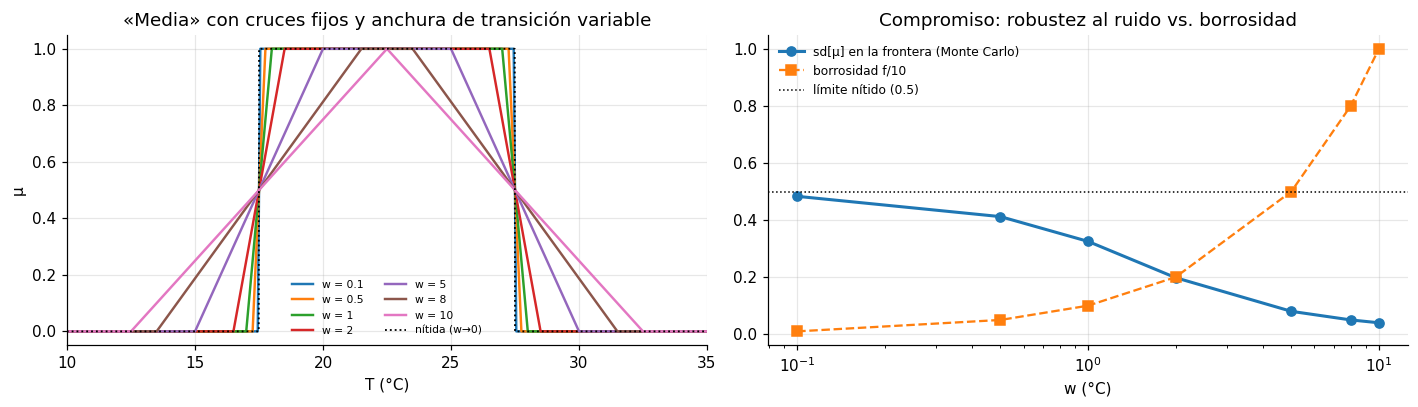

In [20]:
# ── 6.14  Sensibilidad a la anchura w de la transición
def media_w(xx, w):
    return trapmf(xx, T1 - w / 2, T1 + w / 2, T2 - w / 2, T2 + w / 2)

anchos = [0.1, 0.5, 1, 2, 5, 8, 10]
lect_b = T1 + rng.normal(0, SIGMA_M, 50_000) # lecturas con T_real = T1
filas = []
for w in anchos:
    m = media_w(x, w)
    filas.append({"w (°C)": w, "|Media| (°C)": cardinalidad(m, x), "f(Media) (°C)": borrosidad(m, x),
                  "f teórica = w": w, "L = 1/w (1/°C)": 1 / w, "μ_Media(18 °C)": float(media_w(18.0, w)),
                  "sd[μ] en T₁ (MC)": media_w(lect_b, w).std(), "≈ σ_m/w": min(SIGMA_M / w, 0.5)})
sens = pd.DataFrame(filas).set_index("w (°C)")
display(sens.round(4))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for w in anchos:
    axs[0].plot(x, media_w(x, w), lw=1.6, label=f"w = {w:g}")
axs[0].plot(x, clasica.mu("Media", x), "k:", lw=1.2, label="nítida (w→0)")
axs[0].set(title="«Media» con cruces fijos y anchura de transición variable", xlabel="T (°C)", ylabel="μ", xlim=(10, 35))
axs[0].legend(fontsize=7, ncol=2)
axs[1].semilogx(sens.index, sens["sd[μ] en T₁ (MC)"], "o-", lw=2, label="sd[μ] en la frontera (Monte Carlo)")
axs[1].semilogx(sens.index, sens["f(Media) (°C)"] / 10, "s--", lw=1.5, label="borrosidad f/10")
axs[1].axhline(0.5, color="k", ls=":", lw=1, label="límite nítido (0.5)")
axs[1].set(title="Compromiso: robustez al ruido vs. borrosidad", xlabel="w (°C)")
axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretación.**
1. **La cardinalidad es invariante**: $|\text{Media}|=10$ °C para todo $w$, porque las rampas son simétricas respecto de los cruces. La «cantidad» de pertenencia no cambia; solo se redistribuye.
2. **La borrosidad crece linealmente**, $f=w$, tal como se dedujo en §3.7.
3. **La robustez al ruido crece con $w$.** Para $w\gg\sigma_m$, $\mathrm{sd}[\mu]\approx\sigma_m/w$. Para $w\lesssim\sigma_m$ el sistema se comporta como nítido ($\mathrm{sd}\to0.5$). La regla de diseño que se obtiene es que **la anchura de la transición debe ser bastante mayor que la incertidumbre del sensor** ($w\gtrsim5\sigma_m$, unos 2 °C aquí) para aprovechar las ventajas de la representación difusa.
4. **Los grados dependen del diseño**: $\mu_{\text{Media}}(18)$ pasa de 1 ($w=1$) a 0.55 ($w=10$). Los números concretos no son «verdades» físicas, sino consecuencias de decisiones de modelado. Es una de las principales limitaciones del método (§7).
5. El compromiso es claro: transiciones anchas dan robustez pero menos especificidad (más borrosidad); transiciones estrechas dan especificidad pero fragilidad. La trapezoidal elegida ($w=5$ °C, unas 12 σ) está en una zona razonable.

### 6.15 Propagación de errores a través de los operadores [KY, p. 51]

Si los grados de entrada tienen un error $|\delta|\le e$, ¿cuánto puede cambiar el resultado de cada operación? Se busca el peor caso sobre $(a,b)\in[0,1]^2$ y perturbaciones $\delta_a,\delta_b\in\{-e,0,e\}$.

In [21]:
# ── 6.15  Peor caso de amplificación de errores (e = 0.05)
e = 0.05
gg = np.linspace(0, 1, 101); A_, B_ = np.meshgrid(gg, gg)
perturb = [(da, db) for da in (-e, 0, e) for db in (-e, 0, e) if (da, db) != (0, 0)]
operadores = {
    "complemento estándar": lambda p, q: c_estandar(p),
    "Sugeno λ=2":           lambda p, q: c_sugeno(p, 2),
    "∩ min":                i_min, "∩ producto": i_prod, "∩ Łukasiewicz": i_luk, "∩ drástica": i_drastica,
    "∪ max":                u_max, "∪ suma algebraica": u_suma_alg, "∪ suma acotada": u_acotada, "∪ drástica": u_drastica,
}
filas = []
for n, op in operadores.items():
    base = op(A_, B_)
    peor = max(np.abs(op(np.clip(A_ + da, 0, 1), np.clip(B_ + db, 0, 1)) - base).max() for da, db in perturb)
    filas.append({"Operador": n, "Error máx. de salida": peor, "Factor de amplificación (salida / e)": peor / e})
display(pd.DataFrame(filas).set_index("Operador").round(3))

,Error máx. de salida,Factor de amplificación (salida / e)
Operador,,
complemento estándar,0.050,1.000
Sugeno λ=2,0.136,2.727
∩ min,0.050,1.000
∩ producto,0.098,1.950
∩ Łukasiewicz,0.100,2.000
∩ drástica,1.000,20.000
∪ max,0.050,1.000
∪ suma algebraica,0.098,1.950
∪ suma acotada,0.100,2.000


**Interpretación.**
- Se confirma la afirmación de [KY, p. 51]: el **complemento estándar, min y max no amplifican el error** (factor 1).
- El producto, la suma algebraica y las operaciones acotadas pueden **duplicarlo** (factor 2), y el complemento de Sugeno con $\lambda=2$ hasta triplicarlo (factor ≈3, cerca de $a=0$).
- Las operaciones **drásticas** son **discontinuas**: un error de 0.05 puede cambiar el resultado en 1 (factor 20).
- En un contexto experimental, donde los grados de pertenencia se obtienen a partir de mediciones con incertidumbre, este es un argumento sólido a favor de las **operaciones estándar** como elección por defecto, salvo que la semántica del problema exija otra cosa.

### 6.16 Construcción de la función de pertenencia a partir de datos [KY, Cap. 10]

Para responder a la pregunta «¿de dónde salen los parámetros?», se simula el procedimiento de [KY, §10.4, ec. (10.1)]. A $n=30$ «expertos» (p. ej. estudiantes y técnicos del laboratorio) se les pregunta si cada temperatura es «Media» (sí/no). Cada experto tiene sus propios umbrales $l_i\sim\mathcal N(17.5,1.5^2)$ y $u_i\sim\mathcal N(27.5,1.5^2)$. Se toma

$$A(x)=\frac1n\sum_{i=1}^n a_i(x)\qquad(10.1)$$

y luego se ajusta por **mínimos cuadrados** [KY, §10.7, ecs. (10.15)–(10.20)] una trapezoidal y una campana $f(x)=\gamma\,e^{-(x-\alpha)^2/\beta}$, recortada a $[0,1]$ según (10.16).

Trapecio ajustado: Trap(14.67, 19.70, 25.41, 30.46)  → cruces en 17.18 y 27.93 °C   |  E = 0.0525
Campana ajustada:  α = 22.53, β = 31.86, γ = 1.120   |  E = 0.2607
Diseño propuesto (§4.2): Trap(15, 20, 25, 30)  |  E respecto a los datos = 0.1678


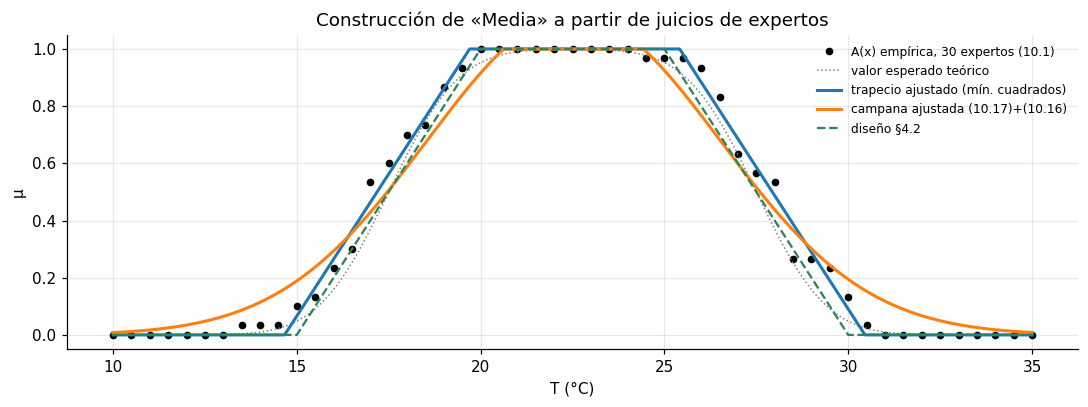

In [22]:
# ── 6.16  Encuesta simulada a expertos + ajuste por mínimos cuadrados ────────
n_exp = 30
l_i = rng.normal(T1, 1.5, n_exp); u_i = rng.normal(T2, 1.5, n_exp)
x_s = np.arange(10, 35.01, 0.5)                                         # temperaturas consultadas
votos = (x_s[None, :] >= l_i[:, None]) & (x_s[None, :] <= u_i[:, None])
A_emp = votos.mean(axis=0)                                              # ec. (10.1)

def trap_param(xx, c1, w1, c2, w2):                                     # trapecio por (centros, anchuras)
    return trapmf(xx, c1 - w1 / 2, c1 + w1 / 2, c2 - w2 / 2, c2 + w2 / 2)
def campana(xx, alpha, beta, gamma):                                    # ec. (10.17)
    return gamma * np.exp(-(xx - alpha) ** 2 / beta)

p_trap, _ = curve_fit(trap_param, x_s, A_emp, p0=[17.5, 5, 27.5, 5], bounds=([10, .2, 20, .2], [25, 15, 35, 15]))
p_bell, _ = curve_fit(campana, x_s, A_emp, p0=[22.5, 50, 1])
fit_trap = trap_param(x_s, *p_trap)
fit_bell = np.clip(campana(x_s, *p_bell), 0, 1)                         # ec. (10.16)
E = lambda y: np.sum((y - A_emp) ** 2)                                  # ec. (10.15)

c1, w1, c2, w2 = p_trap
print(f"Trapecio ajustado: Trap({c1-w1/2:.2f}, {c1+w1/2:.2f}, {c2-w2/2:.2f}, {c2+w2/2:.2f})  → cruces en "
      f"{c1:.2f} y {c2:.2f} °C   |  E = {E(fit_trap):.4f}")
print(f"Campana ajustada:  α = {p_bell[0]:.2f}, β = {p_bell[1]:.2f}, γ = {p_bell[2]:.3f}"
      f"   |  E = {E(fit_bell):.4f}")
print(f"Diseño propuesto (§4.2): Trap(15, 20, 25, 30)  |  E respecto a los datos = {E(trapmf(x_s, 15, 20, 25, 30)):.4f}")

xx = np.linspace(10, 35, 1001)
teo = norm.cdf((xx - T1) / 1.5) * (1 - norm.cdf((xx - T2) / 1.5))      # valor esperado de (10.1)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(x_s, A_emp, "ko", ms=4, label=f"A(x) empírica, {n_exp} expertos (10.1)")
ax.plot(xx, teo, color="gray", lw=1, ls=":", label="valor esperado teórico")
ax.plot(xx, trap_param(xx, *p_trap), lw=2, label="trapecio ajustado (mín. cuadrados)")
ax.plot(xx, np.clip(campana(xx, *p_bell), 0, 1), lw=2, label="campana ajustada (10.17)+(10.16)")
ax.plot(xx, trapmf(xx, 15, 20, 25, 30), lw=1.5, ls="--", color=COLORES["Media"], label="diseño §4.2")
ax.set(title="Construcción de «Media» a partir de juicios de expertos", xlabel="T (°C)", ylabel="μ")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretación.**
- La agregación de juicios **binarios** de muchos expertos produce una función **graduada** (10.1). La vaguedad del concepto aparece como **desacuerdo entre observadores**: es la interpretación «probabilística» de la pertenencia que propone [KY, §10.4].
- Los datos tienen una **meseta**: entre ~21 y ~24 °C todos los expertos dicen «sí». Por eso el **trapecio ajusta mucho mejor** (menor $E$) que la campana, que no puede representar un núcleo extendido.
- Los cruces ajustados quedan cerca de 17.5 y 27.5 °C, y el trapecio propuesto en §4.2 queda próximo al ajustado. Esto da **respaldo empírico** (simulado) a la elección de la forma trapezoidal y de sus parámetros.
- Limitación: los datos son simulados con supuestos propios (umbrales normales con desviación de 1.5 °C). En una aplicación real habría que hacer la encuesta, y el resultado dependería de la población consultada (dependencia del contexto).

### 6.17 Extensión: segunda variable física, el régimen de flujo (número de Reynolds)

Para mostrar que la metodología es general, se define la variable «Régimen de flujo en tubería» sobre un **universo logarítmico**, $z=\log_{10}Re\in[2,5]$. La escala logarítmica es la natural porque $Re$ abarca varios órdenes de magnitud. Las transiciones se colocan en $Re$ = 2000–2600 (laminar → transición) y 3500–4000 (transición → turbulento), de modo que el primer cruce cae en $Re\approx2300$, el valor crítico que suele citarse.

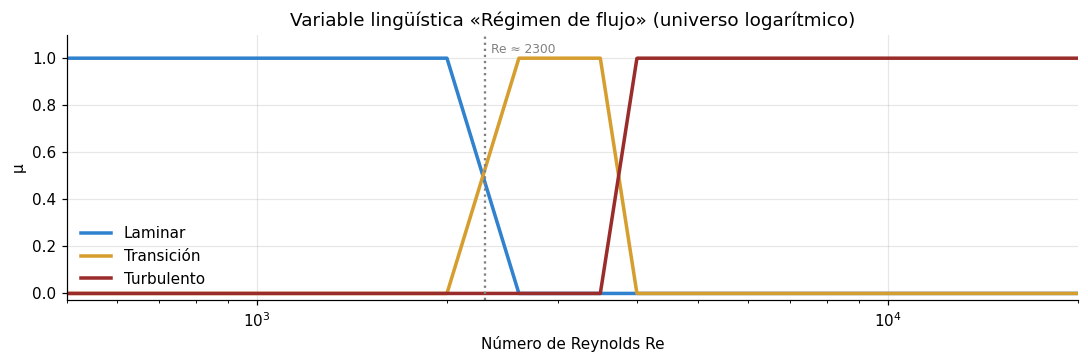

,Laminar,Transición,Turbulento
Re,,,
1500,1.000,0.000,0.000
2100,0.814,0.186,0.000
2300,0.467,0.533,0.000
3000,0.000,1.000,0.000
3800,0.000,0.384,0.616
10000,0.000,0.000,1.000


Cruce laminar/transición en Re ≈ 2280 | cruce transición/turbulento en Re ≈ 3742


In [23]:
# ── 6.17  Variable «régimen de flujo» con universo logarítmico ───────────────
L10 = np.log10
reynolds = VariableLinguistica("Régimen de flujo en tubería", (2.0, 5.0), {
    "Laminar":    lambda z: trapmf(z, 2, 2, L10(2000), L10(2600)),
    "Transición": lambda z: trapmf(z, L10(2000), L10(2600), L10(3500), L10(4000)),
    "Turbulento": lambda z: trapmf(z, L10(3500), L10(4000), 5, 5),
}, unidades="log10(Re)")

z = reynolds.malla(3001); Re = 10 ** z
fig, ax = plt.subplots(figsize=(10, 3.4))
for t, col in zip(reynolds.terminos, ["#3182ce", "#d69e2e", "#9b2c2c"]):
    ax.semilogx(Re, reynolds.mu(t, z), lw=2.3, color=col, label=t)
ax.axvline(2300, color="gray", ls=":"); ax.text(2350, 1.02, "Re ≈ 2300", fontsize=8, color="gray")
ax.set(title="Variable lingüística «Régimen de flujo» (universo logarítmico)", xlabel="Número de Reynolds Re",
       ylabel="μ", ylim=(-0.03, 1.1), xlim=(500, 2e4)); ax.legend(); plt.tight_layout(); plt.show()

Re_m = np.array([1500, 2100, 2300, 3000, 3800, 10_000])
display(pd.DataFrame({t: reynolds.mu(t, L10(Re_m)) for t in reynolds.terminos},
                     index=pd.Index(Re_m, name="Re")).round(3))
print("Cruce laminar/transición en Re ≈", round(10 ** ((L10(2000) + L10(2600)) / 2)),
      "| cruce transición/turbulento en Re ≈", round(10 ** ((L10(3500) + L10(4000)) / 2)))

**Interpretación.**
- Un flujo con $Re=2100$ es «principalmente laminar» (≈0.8), con una componente de transición. Con $Re=3800$ el flujo está a medio camino entre transición y turbulento.
- La representación difusa refleja lo que se observa experimentalmente: la transición laminar–turbulento depende de las perturbaciones de entrada y de la rugosidad, y **no ocurre en un valor único** de $Re$. Usar un umbral nítido en 2300 sería una convención sin respaldo físico.
- La elección del universo (lineal o logarítmico) es en sí misma una **decisión de modelado**: con un universo lineal, las rampas tendrían anchuras visualmente muy distintas.

### 6.18 Contraste con una biblioteca especializada (opcional)

Si `scikit-fuzzy` está instalado, se comparan las implementaciones propias con `skfuzzy.trimf`, `trapmf` y `gaussmf`.

In [24]:
# ── 6.18  Validación cruzada con scikit-fuzzy (si está disponible) ───────────
try:
    import skfuzzy as fuzz
    xs = np.linspace(0, 45, 4501)
    comparaciones = {
        "trimf (12.5, 22.5, 32.5)":   (trimf(xs, 12.5, 22.5, 32.5), fuzz.trimf(xs, [12.5, 22.5, 32.5])),
        "trapmf (15, 20, 25, 30)":    (trapmf(xs, 15, 20, 25, 30),  fuzz.trapmf(xs, [15, 20, 25, 30])),
        "trapmf hombro (0,0,15,20)":  (trapmf(xs, 0, 0, 15, 20),    fuzz.trapmf(xs, [0, 0, 15, 20])),
        "gaussmf (22.5, σ)":          (gaussmf(xs, 22.5, SIGMA),    fuzz.gaussmf(xs, 22.5, SIGMA)),
    }
    for n, (propia, ref) in comparaciones.items():
        print(f"{n:28s} máx |propia − skfuzzy| = {np.abs(propia - ref).max():.2e}")
except ImportError:
    print("scikit-fuzzy no está instalado (es opcional). Para activar esta validación: pip install scikit-fuzzy\n"
          "La corrección de la implementación propia ya quedó verificada con las pruebas unitarias (§6.1f),\n"
          "los α-cortes analíticos (§6.6b) y los teoremas de [KY] (§6.10).")

scikit-fuzzy no está instalado (es opcional). Para activar esta validación: pip install scikit-fuzzy
La corrección de la implementación propia ya quedó verificada con las pruebas unitarias (§6.1f),
los α-cortes analíticos (§6.6b) y los teoremas de [KY] (§6.10).


<a id="7"></a>
## 7. Discusión, conclusiones y limitaciones

### 7.1 Síntesis de resultados propios

| Pregunta | Resultado (sección) |
|---|---|
| ¿Qué familia representa mejor «temperatura media» del laboratorio? | **Trapezoidal**: núcleo extendido (banda de confort), partición de Ruspini, identidad «ni Baja ni Alta» exacta, y mejor ajuste a juicios de expertos simulados (§6.8, §6.16). |
| ¿Cuándo preferir la gaussiana? | Cuando se necesita **derivabilidad**, p. ej. para ajustar parámetros por gradiente (Actividades 4 y 5). Su coste: no es partición de Ruspini, tiene colas infinitas y solapa términos no adyacentes (§6.8). |
| ¿Cuándo la triangular? | Con pocos datos o cuando el concepto tiene un único prototipo. Es la más robusta al ruido ($L=0.1$) pero la más borrosa (§6.6, §6.13). |
| ¿Qué aporta la representación difusa frente a la clásica? | Continuidad (Lipschitz), información graduada, modificadores lingüísticos, y una dispersión **6–12 veces menor** ante ruido de medición en las fronteras (§6.12, §6.13). |
| ¿Qué operaciones usar? | Las **estándar** (min, max, 1−a): sin parámetros, idempotentes, sin amplificación de errores, compatibles con la identidad lingüística (§6.10, §6.15). Las de Łukasiewicz solo si se quiere exclusión mutua entre términos. |
| ¿Se conserva la lógica clásica? | **No del todo.** Ninguna terna (i, u, c) conserva toda el álgebra de Boole: la estándar pierde la contradicción y el tercero excluido; Łukasiewicz pierde la distributividad (§6.10). |

### 7.2 Conclusiones

1. Un conjunto difuso **generaliza** la función característica. La clasificación clásica aparece como caso límite (anchura de transición nula), como un α-corte, o como la etiqueta de máximo grado. El teorema de descomposición muestra que un conjunto difuso equivale a una familia anidada de conjuntos nítidos.
2. Elegir el **universo de discurso**, los **términos** y los **parámetros** es una tarea de modelado guiada por el conocimiento físico del problema: temperaturas de referencia, confort térmico, incertidumbre del sensor. Puede contrastarse con datos de expertos (Cap. 10 de [KY]).
3. La **forma** de la función influye menos que la **posición de los cruces** y la **anchura de las transiciones**. Con los mismos cruces, las tres familias dan grados parecidos ($\pm0.05$ en 18 °C) y la misma cardinalidad. La anchura controla el compromiso entre especificidad (borrosidad) y robustez al ruido, con la regla práctica $w\gtrsim5\sigma_m$.
4. Las operaciones difusas **no son únicas**. Su elección es una decisión semántica con consecuencias numéricas importantes: en el mismo punto, la intersección va de 0 a 0.4 según la t-norma.
5. Desde el punto de vista experimental, la representación difusa responde de forma **gradual y acotada** a la incertidumbre de medición, mientras que la nítida es discontinua y produce conmutaciones espurias cerca de los umbrales.

### 7.3 Limitaciones y análisis crítico

- **Subjetividad y dependencia del contexto.** Los parámetros no se deducen de leyes físicas. Las mismas funciones no servirían para un horno o un criostato, y los grados concretos cambian con el diseño (§6.14). [KY, p. 15] reconoce que construir funciones de pertenencia significativas «es un problema difícil».
- **Precisión excesiva de los grados.** Asignar exactamente 0.6 a 18 °C es también una idealización. Los conjuntos **intervalo-valuados** o de **tipo 2** [KY, §1.3] permitirían representar la incertidumbre *sobre* la función de pertenencia, a costa de más cómputo.
- **Pérdida de leyes clásicas.** Con las operaciones estándar, «Media y no Media» puede ser verdadero en grado 0.5. Esto es coherente con la vaguedad, pero obliga a revisar razonamientos que dependan de la contradicción o del tercero excluido.
- **Gaussianas.** Tienen soporte infinito, así que hay que truncar numéricamente. Además no forman una partición de Ruspini y solapan términos no adyacentes.
- **Triangulares y trapezoidales.** No son derivables en sus vértices, lo que complica la optimización por gradiente.
- **Pertenencia ≠ probabilidad.** La interpretación de los grados debe hacerse con cuidado. La construcción por encuesta (10.1) les da una lectura frecuentista, pero el ruido del sensor es otra fuente de incertidumbre, que la función de pertenencia **no** modela (§6.13).
- **Validación.** La encuesta de §6.16 es simulada. Una validación real exigiría datos de usuarios del laboratorio.

### 7.4 ¿Cuándo es apropiado usar esta representación?

Es apropiada cuando:
- el concepto es intrínsecamente graduado;
- las fronteras nítidas serían arbitrarias;
- las mediciones tienen incertidumbre comparable a la escala de las fronteras;
- se busca combinar conocimiento experto expresado en lenguaje natural con datos numéricos.

Es la base para construir reglas «Si… entonces…» (Actividad 2), controladores (Actividad 3) y sistemas que aprenden sus parámetros (Actividades 4 y 5). **No** es apropiada cuando el problema exige exactitud bivalente (p. ej. cumplimiento de una norma con un umbral legal) ni cuando la incertidumbre es puramente aleatoria y bien caracterizada, en cuyo caso la probabilidad es la herramienta natural.

<a id="8"></a>
## 8. Referencias bibliográficas

**Fuente principal**

- Klir, G. J., y Yuan, B. (1995). *Fuzzy Sets and Fuzzy Logic: Theory and Applications*. Prentice Hall. ISBN 0-13-101171-5.
  - Capítulos y secciones usados: Cap. 1 (§1.1–1.4); Cap. 2 (§2.2, Teo. 2.5); Cap. 3 (§3.1–3.5); §4.2; §8.5; §9.4; Cap. 10 (§10.1–10.4, §10.7).

**Bibliografía de la guía de evaluación**

- Zadeh, L. A. (1965). Fuzzy sets. *Information and Control*, 8(3), 338–353. https://doi.org/10.1016/S0019-9958(65)90241-X
- Ross, T. J. (2010). *Fuzzy Logic with Engineering Applications* (3.ª ed.). Wiley.
- Jang, J.-S. R., Sun, C.-T., y Mizutani, E. (1997). *Neuro-Fuzzy and Soft Computing: A Computational Approach to Learning and Machine Intelligence*. Prentice Hall.
- Documentación de `scikit-fuzzy`: https://pythonhosted.org/scikit-fuzzy/ — y de MATLAB *Fuzzy Logic Toolbox*: https://www.mathworks.com/help/fuzzy/

**Fuentes complementarias**

- Black, M. (1937). Vagueness: An exercise in logical analysis. *Philosophy of Science*, 4(4), 427–455. https://doi.org/10.1086/286476
- Zadeh, L. A. (1975). The concept of a linguistic variable and its application to approximate reasoning—I. *Information Sciences*, 8(3), 199–249. https://doi.org/10.1016/0020-0255(75)90036-5
- Ruspini, E. H. (1969). A new approach to clustering. *Information and Control*, 15(1), 22–32. https://doi.org/10.1016/S0019-9958(69)90591-9 (origen de las «particiones de Ruspini»).
- Yager, R. R. (1980). On a general class of fuzzy connectives. *Fuzzy Sets and Systems*, 4(3), 235–242. https://doi.org/10.1016/0165-0114(80)90013-5
- IEC 60751:2022. *Industrial platinum resistance thermometers and platinum temperature sensors* (tolerancias de clase de las Pt100).
- ISO 1:2022. *Geometrical product specifications (GPS) — Standard reference temperature for the specification of geometrical and dimensional properties* (temperatura de referencia de 20 °C).
- ANSI/ASHRAE Standard 55. *Thermal Environmental Conditions for Human Occupancy*; ISO 7730:2005. *Ergonomics of the thermal environment*.

**Software empleado:** Python 3, NumPy, SciPy, pandas, Matplotlib (versiones impresas en §6.0).